# Google Quick, Draw! — Data Loading, EDA and Preprocessing
> The aim of this part of the project is to classify hand-drawn sketches into eight different object categories using machine learning. Each image contains 28 × 28 grayscale pixels, and the model must predict which category the drawing belongs to. This fits the overall "Learning from Players" project because the drawings are created by players, allowing us to investigate how well different machine learning algorithms recognise visual patterns.

**Data source:** Google Creative Lab, Quick, Draw! Dataset, https://github.com/googlecreativelab/quickdraw-dataset (CC BY 4.0)

## 1. Setup

In [1]:
# ---- Imports ----
from pathlib import Path
import hashlib
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# ---- Project paths (relative, so the notebook runs on anyone's machine) ----
# Layout assumed:  <repo>/notebooks/03_QuickDraw_Classical_MLP_Reviewed.ipynb
#                  <repo>/data/quickdraw/   (raw .npy files + processed .npz)
#                  <repo>/figures/          (saved plots)
quickdraw_dir = Path("../data/quickdraw")
figures_dir = Path("../figures")
quickdraw_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# ---- Reproducibility ----
SEED = 42   # used for sampling (cell below) and for both train_test_split calls

## 2. Download the raw bitmap files (8 classes)
> The dataset comes from Google's publicly available Quick, Draw! dataset, which contains drawings created by players of the Quick, Draw! game. We use the numpy_bitmap files, where each row represents one drawing stored as 784 pixel values (28 × 28). For this project, we use eight categories: airplane, apple, bicycle, cat, fish, guitar, house and tree. These categories provide a manageable selection of different shapes and objects for comparing machine learning models.

In [2]:
# The 8 classes used in this project. The list order defines the label IDs (airplane=0 ... tree=7)
categories = [
    "airplane",
    "apple",
    "bicycle",
    "cat",
    "fish",
    "guitar",
    "house",
    "tree"
]

# Google's public bucket: one .npy file per class, each row = one 28x28 drawing flattened to 784 values
base_url = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/"

for category in categories:
    destination = quickdraw_dir / f"{category}.npy"

    # Skip files we already have (each is ~90-115 MB)
    if destination.exists():
        print(f"{category}: already downloaded")
    else:
        url = f"{base_url}{category}.npy"
        print(f"Downloading {category}...")
        urllib.request.urlretrieve(url, destination)
        print(f"{category}: finished")

print("\nAll selected categories are available.")

airplane: already downloaded
apple: already downloaded
bicycle: already downloaded
cat: already downloaded
fish: already downloaded
guitar: already downloaded
house: already downloaded
tree: already downloaded

All selected categories are available.


## 3. Inspect the raw data

In [4]:
# Check how many drawings each class has, that every drawing has 784 features (28x28),
# and how big each file is on disk
for category in categories:
    path = quickdraw_dir / f"{category}.npy"
    data = np.load(path)

    print(
        f"{category:10s} | "
        f"drawings = {len(data):,} | "
        f"features = {data.shape[1]} | "
        f"size = {path.stat().st_size / 1024**2:.1f} MB"
    )

airplane   | drawings = 151,623 | features = 784 | size = 113.4 MB
apple      | drawings = 144,722 | features = 784 | size = 108.2 MB
bicycle    | drawings = 126,527 | features = 784 | size = 94.6 MB
cat        | drawings = 123,202 | features = 784 | size = 92.1 MB
fish       | drawings = 134,150 | features = 784 | size = 100.3 MB
guitar     | drawings = 120,451 | features = 784 | size = 90.1 MB
house      | drawings = 135,420 | features = 784 | size = 101.3 MB
tree       | drawings = 144,721 | features = 784 | size = 108.2 MB


In [5]:
# Pixel statistics per class on the FULL raw files.
# dtype uint8 => values 0-255 (0 = background, 255 = full stroke).
# Mean intensity is a rough measure of how much "ink" a class uses.
for category in categories:
    data = np.load(quickdraw_dir / f"{category}.npy")

    print(
        f"{category:10s} | "
        f"dtype = {data.dtype} | "
        f"min = {data.min()} | "
        f"max = {data.max()} | "
        f"mean = {data.mean():.2f}"
    )

airplane   | dtype = uint8 | min = 0 | max = 255 | mean = 40.53
apple      | dtype = uint8 | min = 0 | max = 255 | mean = 37.69
bicycle    | dtype = uint8 | min = 0 | max = 255 | mean = 44.18
cat        | dtype = uint8 | min = 0 | max = 255 | mean = 50.66
fish       | dtype = uint8 | min = 0 | max = 255 | mean = 36.50
guitar     | dtype = uint8 | min = 0 | max = 255 | mean = 43.39
house      | dtype = uint8 | min = 0 | max = 255 | mean = 44.06
tree       | dtype = uint8 | min = 0 | max = 255 | mean = 44.11


> The original dataset contains more than 120,000 drawings for every selected category, with each drawing represented by 784 features. The pixel values are stored using the uint8 data type, which represents integers between 0 and 255. The mean pixel intensity provides a rough indication of the amount of drawing present in each image. Differences in stroke density and drawing complexity could affect classification because some sketches contain more visual information than others.

## 4. Balanced random sampling (3,000 per class, seed 42)
> We randomly selected 3,000 drawings from each of the eight categories, giving us a total of 24,000 images. This reduces the amount of data we need to process, making model training and experimentation more manageable. Using the same number of drawings for every category also prevents larger classes from dominating the dataset. Since there are eight equally represented categories, a majority-class classifier would achieve 12.5% accuracy. We sample without replacement so the same original row is not selected twice within a category, and we use random seed 42 to make the sampling reproducible.

In [6]:
samples_per_class = 3000
rng = np.random.default_rng(SEED)   # fixed seed (42) => the same 24,000 drawings every run

X_parts = []
y_parts = []

# Map each class name to an integer label: airplane=0, apple=1, ..., tree=7
class_to_id = {category: i for i, category in enumerate(categories)}

for category in categories:
    data = np.load(quickdraw_dir / f"{category}.npy")

    # Randomly choose 3,000 different drawings (replace=False => no drawing picked twice)
    indices = rng.choice(
        len(data),
        size=samples_per_class,
        replace=False
    )

    sampled = data[indices]

    X_parts.append(sampled)
    y_parts.append(
        np.full(samples_per_class, class_to_id[category])   # label every sampled drawing with its class ID
    )

# Stack into one dataset: X = (24000, 784) raw pixels, y = (24000,) labels
X = np.concatenate(X_parts)
y = np.concatenate(y_parts)

# Shuffle all classes together so the rows are not ordered class by class
shuffle_indices = rng.permutation(len(X))
X = X[shuffle_indices]
y = y[shuffle_indices]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("X dtype:", X.dtype)
print("Classes:", class_to_id)

X shape: (24000, 784)
y shape: (24000,)
X dtype: uint8
Classes: {'airplane': 0, 'apple': 1, 'bicycle': 2, 'cat': 3, 'fish': 4, 'guitar': 5, 'house': 6, 'tree': 7}


## 5. Exploratory data analysis

In [7]:
# Confirm the subset is balanced: every class should have exactly 3,000 images
unique, counts = np.unique(y, return_counts=True)

id_to_class = {v: k for k, v in class_to_id.items()}   # reverse map: label ID -> class name

print("Class distribution:")

for class_id, count in zip(unique, counts):
    print(f"{id_to_class[class_id]:10s}: {count}")

Class distribution:
airplane  : 3000
apple     : 3000
bicycle   : 3000
cat       : 3000
fish      : 3000
guitar    : 3000
house     : 3000
tree      : 3000


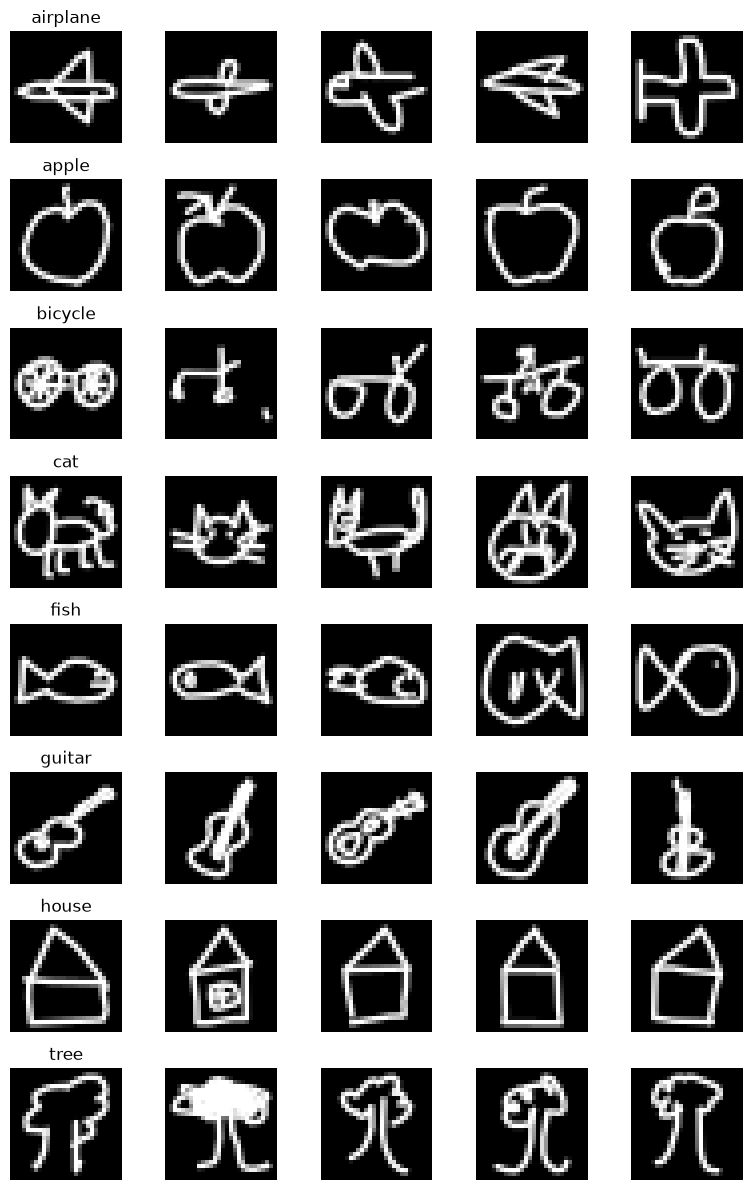

In [7]:
# Sample grid: the first 5 drawings of each class in the shuffled subset
fig, axes = plt.subplots(
    len(categories),
    5,
    figsize=(8, 12)
)

for row, category in enumerate(categories):
    class_id = class_to_id[category]

    # Find 5 samples from this class
    sample_indices = np.where(y == class_id)[0][:5]

    for col, idx in enumerate(sample_indices):
        image = X[idx].reshape(28, 28)   # 784 flat values -> 28x28 image for display

        axes[row, col].imshow(image, cmap="gray")
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_title(category)

plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_sample_grid.png", dpi=150, bbox_inches="tight")
plt.show()

The sample images show that drawing styles vary considerably, even within the same category. Some drawings have clear shapes, while others are simplified, incomplete or difficult to recognise. For example, some bicycles have only basic wheels and lines, while the cat drawings include both faces and full-body sketches. The house drawings appear relatively consistent in the displayed examples. These differences could make certain categories harder for a classifier to recognise. The class-distribution chart also confirms that all eight categories contain exactly 3,000 images.

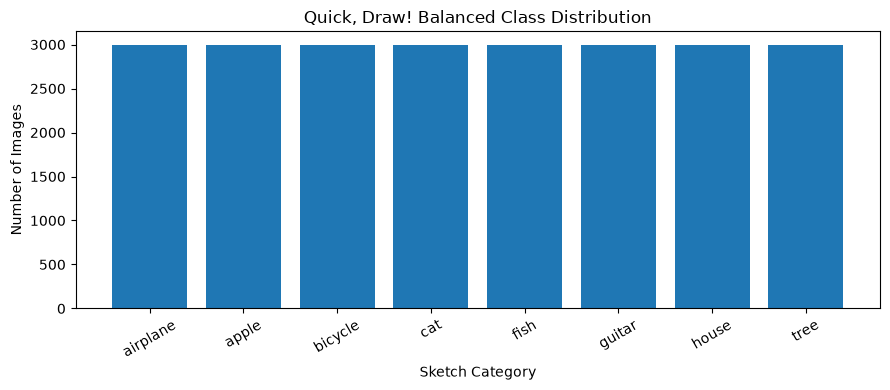

In [8]:
# Bar chart of the class distribution (should be flat: 3,000 each)
class_counts = {
    id_to_class[class_id]: count
    for class_id, count in zip(unique, counts)
}

plt.figure(figsize=(9, 4))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title("Quick, Draw! Balanced Class Distribution")
plt.xlabel("Sketch Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Normalisation and reshaping
> The original pixel values range from 0 to 255, so we divide them by 255 to convert them to values between 0 and 1. This helps keep the inputs on a consistent numerical scale, which is useful for distance-based algorithms and neural network training. We then reshape the drawings from 784 values into 28 × 28 × 1 images, where 28 represents the height and width and 1 represents the grayscale channel. This format is required for the CNN, while classical machine learning models and the MLP can use the same images flattened back into 784 features. Dividing by the fixed value 255 does not use information learned from the dataset, so this step does not introduce data leakage.



In [9]:
# (24000, 784) uint8 0-255  ->  (24000, 28, 28, 1) float32 0-1
X_images = X.reshape(-1, 28, 28, 1).astype("float32") / 255.0

print("CNN input shape:", X_images.shape)
print("Data type:", X_images.dtype)
print("Minimum pixel value:", X_images.min())
print("Maximum pixel value:", X_images.max())

CNN input shape: (24000, 28, 28, 1)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0


## 7. Stratified train / validation / test split (80 / 10 / 10)
We divided the 24,000 drawings into training (80%), validation (10%) and testing (10%) sets. The training set contains 19,200 images and is used to train the models. The validation set contains 2,400 images and is used to compare models and select suitable parameters. The final 2,400 test images are kept separate until the models have been selected, allowing us to evaluate performance on unseen data. Stratified splitting ensures that every category has the same proportion of drawings in each set, with 2,400 training, 300 validation and 300 testing images per category.

In [10]:
# First: 80% train, 20% temporary (stratify=y keeps the 8 classes equally represented)
X_train, X_temp, y_train, y_temp = train_test_split(
    X_images,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Second: split the temporary 20% equally into validation (10%) and test (10%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (19200, 28, 28, 1) (19200,)
Validation: (2400, 28, 28, 1) (2400,)
Test: (2400, 28, 28, 1) (2400,)


In [11]:
# Check stratification worked: expect 2,400 / 300 / 300 images per class
def show_distribution(name, labels):
    unique_ids, counts = np.unique(labels, return_counts=True)

    print(f"\n{name}:")
    for class_id, count in zip(unique_ids, counts):
        print(f"{id_to_class[class_id]:10s}: {count}")

show_distribution("TRAIN", y_train)
show_distribution("VALIDATION", y_val)
show_distribution("TEST", y_test)


TRAIN:
airplane  : 2400
apple     : 2400
bicycle   : 2400
cat       : 2400
fish      : 2400
guitar    : 2400
house     : 2400
tree      : 2400

VALIDATION:
airplane  : 300
apple     : 300
bicycle   : 300
cat       : 300
fish      : 300
guitar    : 300
house     : 300
tree      : 300

TEST:
airplane  : 300
apple     : 300
bicycle   : 300
cat       : 300
fish      : 300
guitar    : 300
house     : 300
tree      : 300


## 8. Save the processed dataset

In [12]:
# Save all splits + class names in one compressed file, so the modelling notebooks
# start from exactly the same data without re-downloading or re-sampling
output_path = quickdraw_dir / "quickdraw_8class_processed.npz"

np.savez_compressed(
    output_path,
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test,
    categories=np.array(categories)
)

print("Saved to:", output_path)
print(f"File size: {output_path.stat().st_size / 1024**2:.1f} MB")

Saved to: ../data/quickdraw/quickdraw_8class_processed.npz
File size: 9.6 MB


## 9. Reload check
Confirms the saved file is complete and correct before anyone models on it.

In [13]:
# Reload the .npz from disk (as the modelling notebooks will) and check it
data = np.load(output_path)
print("Arrays in file:", data.files)

Xtr, ytr = data["X_train"], data["y_train"]
Xva, yva = data["X_val"], data["y_val"]
Xte, yte = data["X_test"], data["y_test"]
saved_categories = data["categories"].tolist()

# 1. Shapes
assert Xtr.shape == (19200, 28, 28, 1) and ytr.shape == (19200,)
assert Xva.shape == (2400, 28, 28, 1) and yva.shape == (2400,)
assert Xte.shape == (2400, 28, 28, 1) and yte.shape == (2400,)

# 2. Pixel values are float32 and inside 0-1
for arr in (Xtr, Xva, Xte):
    assert arr.dtype == np.float32 and arr.min() >= 0.0 and arr.max() <= 1.0

# 3. Exactly 2,400 / 300 / 300 images per class, and class names saved in the right order
assert (np.bincount(ytr) == 2400).all()
assert (np.bincount(yva) == 300).all()
assert (np.bincount(yte) == 300).all()
assert saved_categories == categories

# 4. Reloaded arrays are identical to what was saved
assert np.array_equal(Xtr, X_train) and np.array_equal(ytr, y_train)
assert np.array_equal(Xte, X_test) and np.array_equal(yte, y_test)

# 5. Leakage check: hash every image and count images shared between splits.
#    We sampled without replacement, so overlaps could only come from two players
#    producing pixel-identical drawings (e.g. near-blank sketches). Report, don't hide.
def image_hashes(arr):
    return {hashlib.md5(img.tobytes()).hexdigest() for img in arr}

h_tr, h_va, h_te = image_hashes(Xtr), image_hashes(Xva), image_hashes(Xte)
print("Identical images shared between splits:",
      {"train-val": len(h_tr & h_va), "train-test": len(h_tr & h_te), "val-test": len(h_va & h_te)})

print("All reload checks passed.")

Arrays in file: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'categories']
Identical images shared between splits: {'train-val': 0, 'train-test': 0, 'val-test': 0}
All reload checks passed.


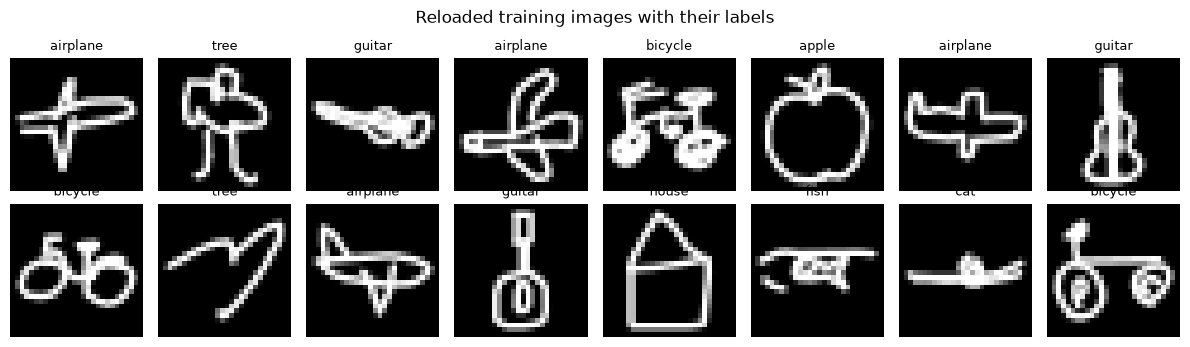

In [14]:
# Visual check on the RELOADED data: do the labels still match the pictures?
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
check_rng = np.random.default_rng(SEED)   # separate RNG so this plot doesn't affect anything else
picks = check_rng.choice(len(Xtr), size=16, replace=False)

for ax, i in zip(axes.ravel(), picks):
    ax.imshow(Xtr[i].squeeze(), cmap="gray")
    ax.set_title(saved_categories[ytr[i]], fontsize=9)
    ax.axis("off")

fig.suptitle("Reloaded training images with their labels")
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_reload_check.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Summary
> We prepared a balanced Quick Draw dataset containing 24,000 drawings across eight categories. Each image was normalised to the range 0–1 and reshaped into a 28 × 28 × 1 grayscale representation. The dataset was divided into 19,200 training, 2,400 validation and 2,400 testing images using a reproducible stratified split. The processed dataset is saved as ../data/quickdraw/quickdraw_8class_processed.npz so that the different models can use the same data. The next stage is to train classical machine learning models and an MLP on flattened pixel values, then compare their performance against the CNN.

## 11. Classical Machine Learning Experiments

This section evaluates how accurately standard classifiers recognise sketches from eight Quick Draw categories when each 28 × 28 grayscale image is represented by 784 normalised pixel values. We evaluate Logistic Regression, Decision Trees, k-Nearest Neighbours (k-NN) and Random Forest, alongside a majority-class reference model.

**Experimental protocol.** All models use the same 24,000-image subset prepared above (seed 42, stratified 80/10/10 split). The 19,200 training images are used for fitting and cross-validation. The 2,400 validation images are used for comparing configurations. The 2,400 final test images are reserved for final evaluation, after model settings have been selected. Fixed seeds and consistent evaluation metrics support a reproducible comparison.

### 11.1. Dataset representation

> For classical classifiers, each `(28, 28, 1)` grayscale image is flattened into a vector of 784 pixel values. This changes only the array shape; it does not alter pixel values or class labels. Pixels have already been scaled to `[0, 1]` during preprocessing. The models below load the existing processed file without resampling or changing the agreed train/validation/test split.

In [15]:
# Load and verify the same fixed dataset used for all classification experiments.
# This cell is independently runnable after Sections 1-10: it reloads the saved data.
from pathlib import Path
import numpy as np

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
processed_path = project_root / "data" / "quickdraw" / "quickdraw_8class_processed.npz"
classical_figures_dir = project_root / "figures"
classical_results_dir = project_root / "results"
classical_figures_dir.mkdir(parents=True, exist_ok=True)
classical_results_dir.mkdir(parents=True, exist_ok=True)

if not processed_path.is_file():
    raise FileNotFoundError(
        f"Missing {processed_path}. Run Sections 7-9 to save the existing .npz "
        "before starting the classification experiments."
    )

with np.load(processed_path, allow_pickle=False) as saved:
    # Deliberately DO NOT load saved["X_test"] or saved["y_test"] during tuning.
    cls_X_train = saved["X_train"]
    cls_y_train = saved["y_train"]
    cls_X_val = saved["X_val"]
    cls_y_val = saved["y_val"]
    cls_classes = saved["categories"].tolist()

expected_classes = [
    "airplane", "apple", "bicycle", "cat", "fish", "guitar", "house", "tree"
]
assert cls_classes == expected_classes, "Unexpected category order: check the .npz file."
assert cls_X_train.shape == (19200, 28, 28, 1)
assert cls_X_val.shape == (2400, 28, 28, 1)
assert cls_y_train.shape == (19200,)
assert cls_y_val.shape == (2400,)
assert np.array_equal(np.bincount(cls_y_train, minlength=8), np.full(8, 2400))
assert np.array_equal(np.bincount(cls_y_val, minlength=8), np.full(8, 300))
assert cls_X_train.dtype == np.float32 and cls_X_val.dtype == np.float32
assert 0 <= cls_X_train.min() <= cls_X_train.max() <= 1
assert 0 <= cls_X_val.min() <= cls_X_val.max() <= 1

# Each 28 x 28 image becomes one flat vector of 784 values; no pixels are altered.
cls_X_train_flat = cls_X_train.reshape(len(cls_X_train), -1)
cls_X_val_flat = cls_X_val.reshape(len(cls_X_val), -1)
assert cls_X_train_flat.shape == (19200, 784)
assert cls_X_val_flat.shape == (2400, 784)

print("Processed dataset:", processed_path)
print("Training features:", cls_X_train_flat.shape)
print("Validation features:", cls_X_val_flat.shape)
print("Categories:", cls_classes)
print("Train/validation examples per class:", np.bincount(cls_y_train), np.bincount(cls_y_val))
print("Final test data is deliberately NOT loaded during model selection.")

Processed dataset: /Users/aryan/Documents/Heriot Watt/HWU Year-4/Data Mining & Machine Learning /Courseworks/uickdraw-f20dl-main/data/quickdraw/quickdraw_8class_processed.npz
Training features: (19200, 784)
Validation features: (2400, 784)
Categories: ['airplane', 'apple', 'bicycle', 'cat', 'fish', 'guitar', 'house', 'tree']
Train/validation examples per class: [2400 2400 2400 2400 2400 2400 2400 2400] [300 300 300 300 300 300 300 300]
Final test data is deliberately NOT loaded during model selection.


### 11.2. Evaluation metrics and experiment setup

> **Performance measures.** Accuracy is the proportion of correctly classified drawings. Macro precision, macro recall and macro F1 give each of the eight classes equal weight. Training and prediction time are recorded separately.

> **Generalisation.** Training and validation accuracy are compared to examine overfitting. For k-NN, training accuracy is estimated on 800 fixed training examples to limit computation; validation metrics use all 2,400 images. Decision Tree hyperparameters are selected using stratified ten-fold cross-validation on training data only. The executed cells below produce the corresponding comparison tables.

In [16]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.exceptions import ConvergenceWarning

# Store all measured results for the final comparison table.
classical_rows = []
classical_models = {}
classical_val_predictions = {}


def classical_train_and_evaluate(family, setting, classifier, *,
                             fitted=False, fit_seconds=None,
                             train_sample_size=None, predict_batch_size=None):
    """Fit on training data only; evaluate on validation data only.

    For a tuned Decision Tree, fitted=True accepts the model already refitted by
    GridSearchCV, avoiding redundant fitting. Training accuracy may be sampled
    for k-NN to avoid expensive predictions on all 19,200 training examples.
    """
    model_key = f"{family} | {setting}"
    if fitted:
        assert fit_seconds is not None
        fit_duration = fit_seconds
        convergence_warnings = 0
    else:
        start_fit = time.perf_counter()
        with warnings.catch_warnings(record=True) as captured:
            warnings.simplefilter("always", ConvergenceWarning)
            classifier.fit(cls_X_train_flat, cls_y_train)
        fit_duration = time.perf_counter() - start_fit
        convergence_warnings = sum(
            issubclass(w.category, ConvergenceWarning) for w in captured
        )

    # Splitting validation into small batches reduces peak memory use in k-NN.
    start_predict = time.perf_counter()
    if predict_batch_size is None:
        val_pred = classifier.predict(cls_X_val_flat)
    else:
        val_pred = np.concatenate([
            classifier.predict(cls_X_val_flat[i:i + predict_batch_size])
            for i in range(0, len(cls_X_val_flat), predict_batch_size)
        ])
    predict_duration = time.perf_counter() - start_predict

    if train_sample_size is not None:
        # A fixed subset is used ONLY for the training-accuracy diagnostic.
        fixed_rng = np.random.default_rng(2026)
        selected = fixed_rng.choice(
            len(cls_X_train_flat),
            size=min(train_sample_size, len(cls_X_train_flat)),
            replace=False
        )
        train_pred = classifier.predict(cls_X_train_flat[selected])
        train_acc = accuracy_score(cls_y_train[selected], train_pred)
        train_count = len(selected)
    else:
        train_pred = classifier.predict(cls_X_train_flat)
        train_acc = accuracy_score(cls_y_train, train_pred)
        train_count = len(cls_y_train)

    row = {
        "Model": family,
        "Settings": setting,
        "Train accuracy": train_acc,
        "Train accuracy rows": train_count,
        "Validation accuracy": accuracy_score(cls_y_val, val_pred),
        "Macro precision": precision_score(cls_y_val, val_pred, average="macro", zero_division=0),
        "Macro recall": recall_score(cls_y_val, val_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(cls_y_val, val_pred, average="macro", zero_division=0),
        "Fit seconds": fit_duration,
        "Predict seconds": predict_duration,
        "Convergence warnings": convergence_warnings,
    }
    classical_rows.append(row)
    classical_models[model_key] = classifier
    classical_val_predictions[model_key] = val_pred
    print(f"{model_key}: val accuracy={row['Validation accuracy']:.4f}, "
          f"macro F1={row['Macro F1']:.4f}, fit={fit_duration:.2f}s, "
          f"predict={predict_duration:.2f}s")
    if convergence_warnings:
        print("  WARNING: Solver did not fully converge; inspect max_iter and results.")
    return row, model_key


def classical_show_rows(family=None):
    """Display measured results, without inventing any scores."""
    frame = pd.DataFrame(classical_rows)
    if family is not None:
        frame = frame.loc[frame["Model"] == family]
    if frame.empty:
        print("No experiments recorded yet.")
        return
    display(frame.round(4).reset_index(drop=True))

print("Evaluation helper ready. Models train on 19,200 images; validation uses 2,400.")

Evaluation helper ready. Models train on 19,200 images; validation uses 2,400.


### 11.3. Majority-class reference model

> This reference classifier predicts the most frequent training class without examining image features. Since each of the eight categories has equal representation, the expected validation accuracy is 12.5%. It provides a minimum reference for measuring the benefit of learning from pixel patterns. Other evaluation measures and runtime are calculated below.

In [17]:
# A dummy model gives us a fair reference score before learning from pixel patterns.
_, classical_dummy_key = classical_train_and_evaluate(
    "Majority baseline", "most_frequent",
    DummyClassifier(strategy="most_frequent")
)
classical_show_rows("Majority baseline")

Majority baseline | most_frequent: val accuracy=0.1250, macro F1=0.0278, fit=0.01s, predict=0.00s


,Model,Settings,Train accuracy,Train accuracy rows,Validation accuracy,Macro precision,Macro recall,Macro F1,Fit seconds,Predict seconds,Convergence warnings
0,Majority baseline,most_frequent,0.125,19200,0.125,0.0156,0.125,0.0278,0.006,0.0008,0


### 11.4. Logistic Regression

> Multiclass Logistic Regression learns linear combinations of the 784 normalised pixel features. Three values of `C` (0.1, 1 and 10) are compared using the `lbfgs` solver with a limit of 400 iterations. Smaller `C` applies stronger regularisation; `max_iter` is an iteration limit, not a learning rate.

> **Results.** The strongest validation macro F1 was **0.8392 at C = 0.1**. Increasing `C` improved training accuracy (0.8642 to 0.8810) but reduced validation macro F1 (0.8392 to 0.8042), consistent with reduced generalisation. The `C = 10` fit produced a convergence warning, so its result should be interpreted with that limitation.

In [18]:
# C controls the strength of L2 regularisation: smaller C = stronger penalty.
# This is appropriate for scikit-learn's lbfgs LogisticRegression solver.
classical_lr_keys = []
for c_value in (0.1, 1.0, 10.0):
    model = LogisticRegression(
        C=c_value, solver="lbfgs", max_iter=400, random_state=42
    )
    _, key = classical_train_and_evaluate(
        "Logistic Regression", f"C={c_value:g}, solver=lbfgs", model
    )
    classical_lr_keys.append(key)

classical_show_rows("Logistic Regression")
classical_lr_rows = pd.DataFrame(classical_rows).query("Model == 'Logistic Regression'")
classical_best_lr = classical_lr_rows.sort_values("Macro F1", ascending=False).iloc[0]
classical_best_lr_key = f"Logistic Regression | {classical_best_lr['Settings']}"
print("Best Logistic Regression by VALIDATION macro F1:", classical_best_lr_key)

Logistic Regression | C=0.1, solver=lbfgs: val accuracy=0.8392, macro F1=0.8392, fit=1.95s, predict=0.00s
Logistic Regression | C=1, solver=lbfgs: val accuracy=0.8204, macro F1=0.8203, fit=2.87s, predict=0.00s
Logistic Regression | C=10, solver=lbfgs: val accuracy=0.8050, macro F1=0.8042, fit=3.94s, predict=0.00s


,Model,Settings,Train accuracy,Train accuracy rows,Validation accuracy,Macro precision,Macro recall,Macro F1,Fit seconds,Predict seconds,Convergence warnings
0,Logistic Regression,"C=0.1, solver=lbfgs",0.8642,19200,0.8392,0.8394,0.8392,0.8392,1.9504,0.0025,0
1,Logistic Regression,"C=1, solver=lbfgs",0.8747,19200,0.8204,0.8204,0.8204,0.8203,2.8730,0.0014,0
2,Logistic Regression,"C=10, solver=lbfgs",0.8810,19200,0.8050,0.8040,0.8050,0.8042,3.9383,0.0008,1


Best Logistic Regression by VALIDATION macro F1: Logistic Regression | C=0.1, solver=lbfgs


### 11.5. Decision Tree training and parameter selection

> Decision Trees split the dataset according to pixel intensities. An unrestricted tree is compared with configurations controlling the split criterion, maximum depth and minimum samples per leaf. Six configurations are evaluated with stratified ten-fold cross-validation on the training set; the best is refitted on all training examples.

> **Results.** The highest cross-validation macro F1 was **0.7319** (standard deviation **0.0077**) using **entropy**, **maximum depth 12** and **five samples per leaf**. This configuration obtained validation macro F1 **0.7349**. The validation set was not used to choose the tree parameters.

In [19]:
# Default/unrestricted tree is a useful overfitting reference.
_, classical_default_tree_key = classical_train_and_evaluate(
    "Decision Tree (default)", "criterion=gini, max_depth=None, min_samples_leaf=1",
    DecisionTreeClassifier(random_state=42)
)

# 10-fold stratified CV uses the training set ONLY, not the held-out validation/test.
classical_tree_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
classical_tree_grid = [
    # Four Gini configurations for depth and leaf-size comparisons.
    {"criterion": ["gini"], "max_depth": [12, 24], "min_samples_leaf": [1, 5]},
    # Two entropy configurations for an additional criterion comparison.
    {"criterion": ["entropy"], "max_depth": [12], "min_samples_leaf": [1, 5]},
]
classical_tree_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=classical_tree_grid,
    scoring="f1_macro",
    cv=classical_tree_cv,
    n_jobs=1,                  # keep memory manageable on a Mac laptop
    refit=True,               # refit best CV model on the entire training split
    return_train_score=True,
    error_score="raise"
)

start_cv = time.perf_counter()
classical_tree_search.fit(cls_X_train_flat, cls_y_train)
classical_cv_seconds = time.perf_counter() - start_cv
print(f"10-fold Decision Tree grid search completed in {classical_cv_seconds:.1f} seconds")
print("Best CV parameters:", classical_tree_search.best_params_)
print("Best mean CV macro F1:", round(classical_tree_search.best_score_, 4))

# Convert every hyperparameter combination into a readable table.
classical_tree_cv_table = pd.DataFrame(classical_tree_search.cv_results_)[[
    "param_criterion", "param_max_depth", "param_min_samples_leaf",
    "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"
]].rename(columns={
    "param_criterion": "Criterion",
    "param_max_depth": "Max depth",
    "param_min_samples_leaf": "Min samples leaf",
    "mean_train_score": "Train macro F1 (CV)",
    "mean_test_score": "CV macro F1",
    "std_test_score": "CV F1 std",
    "rank_test_score": "Rank"
}).sort_values("Rank")
display(classical_tree_cv_table.round(4).reset_index(drop=True))
classical_tree_cv_table.to_csv(
    classical_results_dir / "quickdraw_classical_tree_cv.csv", index=False
)

# GridSearchCV has already refitted the best tree; do not train it again.
classical_tree_setting = ", ".join(
    f"{name}={value}" for name, value in classical_tree_search.best_params_.items()
)
_, classical_best_tree_key = classical_train_and_evaluate(
    "Decision Tree (tuned)", classical_tree_setting,
    classical_tree_search.best_estimator_,
    fitted=True,
    fit_seconds=classical_tree_search.refit_time_
)
classical_show_rows()

Decision Tree (default) | criterion=gini, max_depth=None, min_samples_leaf=1: val accuracy=0.7121, macro F1=0.7121, fit=3.83s, predict=0.00s
10-fold Decision Tree grid search completed in 175.9 seconds
Best CV parameters: {'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 5}
Best mean CV macro F1: 0.7319


,Criterion,Max depth,Min samples leaf,Train macro F1 (CV),CV macro F1,CV F1 std,Rank
0,entropy,12,5,0.8978,0.7319,0.0077,1
1,entropy,12,1,0.9513,0.7274,0.0077,2
2,gini,12,5,0.8813,0.7208,0.0126,3
3,gini,24,5,0.8970,0.7180,0.0119,4
4,gini,12,1,0.9346,0.7155,0.0124,5
5,gini,24,1,0.9998,0.7056,0.0075,6


Decision Tree (tuned) | criterion=entropy, max_depth=12, min_samples_leaf=5: val accuracy=0.7342, macro F1=0.7349, fit=3.37s, predict=0.00s


,Model,Settings,Train accuracy,Train accuracy rows,Validation accuracy,Macro precision,Macro recall,Macro F1,Fit seconds,Predict seconds,Convergence warnings
0,Majority baseline,most_frequent,0.1250,19200,0.1250,0.0156,0.1250,0.0278,0.0060,0.0008,0
1,Logistic Regression,"C=0.1, solver=lbfgs",0.8642,19200,0.8392,0.8394,0.8392,0.8392,1.9504,0.0025,0
2,Logistic Regression,"C=1, solver=lbfgs",0.8747,19200,0.8204,0.8204,0.8204,0.8203,2.8730,0.0014,0
3,Logistic Regression,"C=10, solver=lbfgs",0.8810,19200,0.8050,0.8040,0.8050,0.8042,3.9383,0.0008,1
4,Decision Tree (default),"criterion=gini, max_depth=None, min_samples_le...",1.0000,19200,0.7121,0.7123,0.7121,0.7121,3.8326,0.0008,0
5,Decision Tree (tuned),"criterion=entropy, max_depth=12, min_samples_l...",0.8958,19200,0.7342,0.7368,0.7342,0.7349,3.3707,0.0023,0


### 11.6. Decision Tree generalisation analysis

> The unrestricted tree achieved **100.00% training accuracy** but only **71.21% validation accuracy**, indicating substantial overfitting. The tuned tree achieved **89.58% training accuracy** and **73.42% validation accuracy**. Restricting complexity reduced the training–validation gap and improved performance on unseen validation drawings. The cross-validation plot compares training-fold and held-out-fold macro F1 for each tested parameter combination.

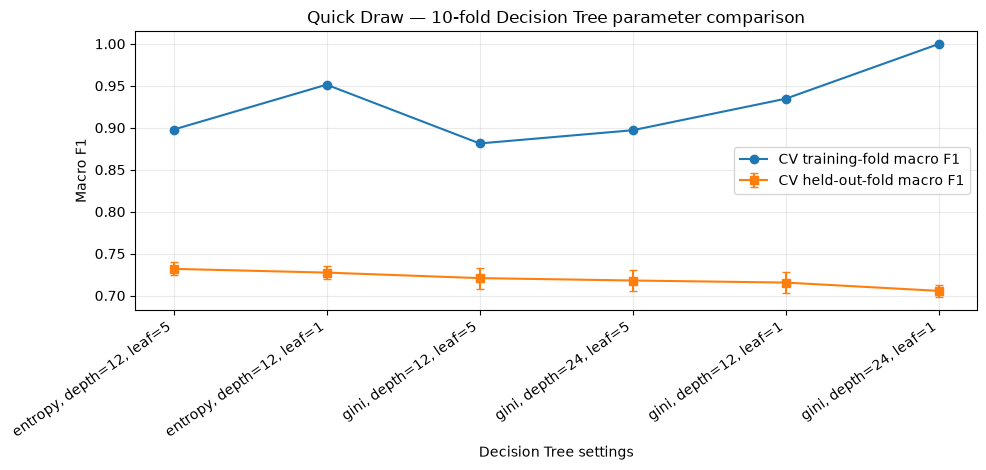

Decision Tree (default) | criterion=gini, max_depth=None, min_samples_leaf=1: train accuracy 1.0000, validation accuracy 0.7121, gap +0.2879
Decision Tree (tuned) | criterion=entropy, max_depth=12, min_samples_leaf=5: train accuracy 0.8958, validation accuracy 0.7342, gap +0.1616


In [20]:
# Compare training and held-out cross-validation performance for each tree setting.
plot_table = classical_tree_cv_table.sort_values("Rank").reset_index(drop=True)
plot_labels = [
    f"{row['Criterion']}, depth={row['Max depth']}, leaf={row['Min samples leaf']}"
    for _, row in plot_table.iterrows()
]
x_positions = np.arange(len(plot_labels))
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(x_positions, plot_table["Train macro F1 (CV)"], "o-", label="CV training-fold macro F1")
ax.errorbar(
    x_positions, plot_table["CV macro F1"],
    yerr=plot_table["CV F1 std"], fmt="s-", capsize=3,
    label="CV held-out-fold macro F1"
)
ax.set_xticks(x_positions, plot_labels, rotation=35, ha="right")
ax.set_ylabel("Macro F1")
ax.set_xlabel("Decision Tree settings")
ax.set_title("Quick Draw — 10-fold Decision Tree parameter comparison")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(classical_figures_dir / "quickdraw_classical_tree_cv.png", dpi=160)
plt.show()

def classical_find_row(key):
    family, setting = key.split(" | ", 1)
    return next(
        row for row in classical_rows
        if row["Model"] == family and row["Settings"] == setting
    )

for key in (classical_default_tree_key, classical_best_tree_key):
    row = classical_find_row(key)
    print(f"{key}: train accuracy {row['Train accuracy']:.4f}, "
          f"validation accuracy {row['Validation accuracy']:.4f}, "
          f"gap {row['Train accuracy'] - row['Validation accuracy']:+.4f}")

### 11.6.1. Effect of training-set size

> The selected Decision Tree is retrained using 40%, 70% and 100% of the original training partition, while the validation images remain unchanged. Validation accuracy increased from **70.17%** to **72.46%** and then **73.42%**, suggesting that additional training examples improved generalisation for this classifier. The final test set is not involved.

,Training fraction,Training rows,Training accuracy,Validation accuracy,Validation macro F1,Fit seconds
2,0.4,7680,0.8934,0.7017,0.7015,1.2801
1,0.7,13440,0.8975,0.7246,0.7237,2.5097
0,1.0,19200,0.8958,0.7342,0.7349,4.0467


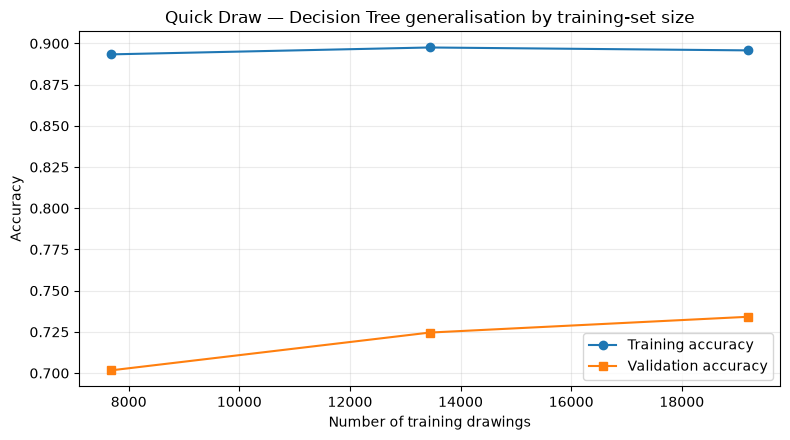

In [21]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split as sklearn_train_test_split

classical_size_results = []
for fraction in (1.0, 0.70, 0.40):
    if fraction == 1.0:
        selected_rows = np.arange(len(cls_y_train))
    else:
        # Stratified sampling from the TRAINING partition, never from validation/test.
        selected_rows, _ = sklearn_train_test_split(
            np.arange(len(cls_y_train)),
            train_size=fraction,
            stratify=cls_y_train,
            random_state=42
        )
    reduced_tree = clone(classical_tree_search.best_estimator_)
    start = time.perf_counter()
    reduced_tree.fit(cls_X_train_flat[selected_rows], cls_y_train[selected_rows])
    seconds = time.perf_counter() - start
    train_acc = accuracy_score(
        cls_y_train[selected_rows],
        reduced_tree.predict(cls_X_train_flat[selected_rows])
    )
    val_pred = reduced_tree.predict(cls_X_val_flat)
    val_acc = accuracy_score(cls_y_val, val_pred)
    classical_size_results.append({
        "Training fraction": fraction,
        "Training rows": len(selected_rows),
        "Training accuracy": train_acc,
        "Validation accuracy": val_acc,
        "Validation macro F1": f1_score(cls_y_val, val_pred, average="macro", zero_division=0),
        "Fit seconds": seconds
    })

classical_size_table = pd.DataFrame(classical_size_results).sort_values("Training rows")
display(classical_size_table.round(4))
classical_size_table.to_csv(classical_results_dir / "quickdraw_classical_tree_training_size.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(classical_size_table["Training rows"], classical_size_table["Training accuracy"], "o-", label="Training accuracy")
ax.plot(classical_size_table["Training rows"], classical_size_table["Validation accuracy"], "s-", label="Validation accuracy")
ax.set_xlabel("Number of training drawings")
ax.set_ylabel("Accuracy")
ax.set_title("Quick Draw — Decision Tree generalisation by training-set size")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(classical_figures_dir / "quickdraw_classical_tree_training_size.png", dpi=160)
plt.show()

### 11.7. k-Nearest Neighbours

> k-NN predicts a class from neighbouring labelled drawings in the 784-dimensional pixel space. The images are already normalised to `[0, 1]`. Values `k = 3`, `5` and `7` are compared on the same validation data using Euclidean distance and uniform neighbour weights.

> **Results.** **k = 5** achieved the strongest validation accuracy (**89.54%**) and macro F1 (**0.8930**), although the improvement over `k = 3` was small. Validation predictions use all 2,400 images and are processed in batches of 400 to manage memory. The training-accuracy diagnostic uses 800 fixed examples, whereas fitting uses all 19,200 training images.

In [22]:
classical_knn_keys = []
for k in (3, 5, 7):
    print(f"Starting k-NN validation experiment for k={k} (all 2,400 validation images)...")
    _, key = classical_train_and_evaluate(
        "k-NN", f"k={k}, uniform weights, Euclidean distance",
        KNeighborsClassifier(
            n_neighbors=k, weights="uniform", metric="euclidean",
            algorithm="brute", n_jobs=1
        ),
        train_sample_size=800,        # only for the train-accuracy diagnostic
        predict_batch_size=400        # validation still evaluates all 2,400 rows
    )
    classical_knn_keys.append(key)
classical_show_rows("k-NN")

classical_knn_rows = pd.DataFrame(classical_rows).query("Model == 'k-NN'")
classical_best_knn = classical_knn_rows.sort_values("Macro F1", ascending=False).iloc[0]
classical_best_knn_key = f"k-NN | {classical_best_knn['Settings']}"
print("Best k-NN by VALIDATION macro F1:", classical_best_knn_key)

Starting k-NN validation experiment for k=3 (all 2,400 validation images)...
k-NN | k=3, uniform weights, Euclidean distance: val accuracy=0.8946, macro F1=0.8917, fit=0.01s, predict=0.69s
Starting k-NN validation experiment for k=5 (all 2,400 validation images)...
k-NN | k=5, uniform weights, Euclidean distance: val accuracy=0.8954, macro F1=0.8930, fit=0.00s, predict=0.58s
Starting k-NN validation experiment for k=7 (all 2,400 validation images)...
k-NN | k=7, uniform weights, Euclidean distance: val accuracy=0.8904, macro F1=0.8870, fit=0.00s, predict=0.55s


,Model,Settings,Train accuracy,Train accuracy rows,Validation accuracy,Macro precision,Macro recall,Macro F1,Fit seconds,Predict seconds,Convergence warnings
0,k-NN,"k=3, uniform weights, Euclidean distance",0.9325,800,0.8946,0.8991,0.8946,0.8917,0.0145,0.6868,0
1,k-NN,"k=5, uniform weights, Euclidean distance",0.9238,800,0.8954,0.8996,0.8954,0.8930,0.0044,0.5794,0
2,k-NN,"k=7, uniform weights, Euclidean distance",0.9075,800,0.8904,0.8949,0.8904,0.8870,0.0047,0.5511,0


Best k-NN by VALIDATION macro F1: k-NN | k=5, uniform weights, Euclidean distance


### 11.8. Parameter comparison

> The plots below show how validation macro F1 changes with regularisation strength in Logistic Regression and with neighbourhood size in k-NN. These comparisons help explain the effects of changing model settings under a consistent validation protocol.

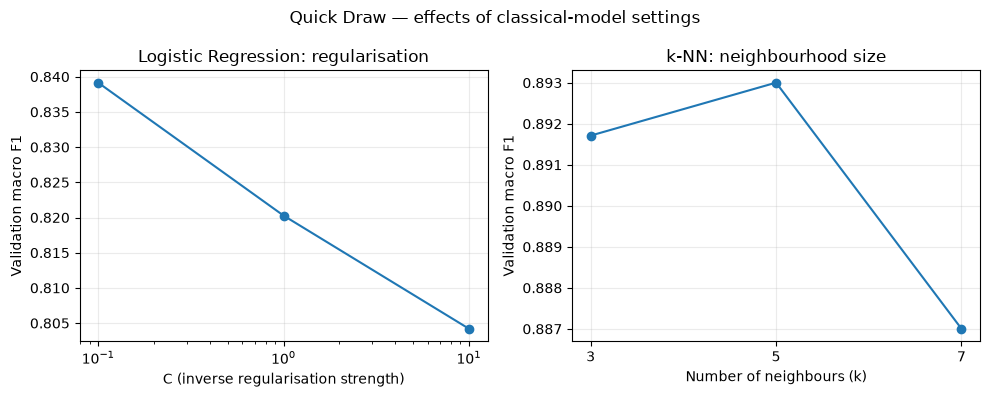

In [23]:
# Plot the validation macro F1 of all Logistic Regression and k-NN settings.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

lr_plot = pd.DataFrame(classical_rows).query("Model == 'Logistic Regression'").copy()
lr_plot["C"] = lr_plot["Settings"].str.extract(r"C=([0-9.]+)").astype(float)
lr_plot = lr_plot.sort_values("C")
axes[0].plot(lr_plot["C"], lr_plot["Macro F1"], "o-")
axes[0].set_xscale("log")
axes[0].set_xlabel("C (inverse regularisation strength)")
axes[0].set_ylabel("Validation macro F1")
axes[0].set_title("Logistic Regression: regularisation")
axes[0].grid(alpha=0.25)

knn_plot = pd.DataFrame(classical_rows).query("Model == 'k-NN'").copy()
knn_plot["k"] = knn_plot["Settings"].str.extract(r"k=(\d+)").astype(int)
knn_plot = knn_plot.sort_values("k")
axes[1].plot(knn_plot["k"], knn_plot["Macro F1"], "o-")
axes[1].set_xticks(sorted(knn_plot["k"].tolist()))
axes[1].set_xlabel("Number of neighbours (k)")
axes[1].set_ylabel("Validation macro F1")
axes[1].set_title("k-NN: neighbourhood size")
axes[1].grid(alpha=0.25)

fig.suptitle("Quick Draw — effects of classical-model settings")
fig.tight_layout()
fig.savefig(classical_figures_dir / "quickdraw_classical_parameter_effects.png", dpi=160)
plt.show()

### 11.9. Random Forest comparison

> Random Forest aggregates the predictions of multiple decision trees. The 100-tree ensemble with `min_samples_leaf = 2` achieved **89.08% validation accuracy** and **0.8907 macro F1**, substantially outperforming either individual Decision Tree. Its **99.88% training accuracy** nevertheless indicates a remaining training–validation gap.

In [25]:
RUN_CLASSICAL_RANDOM_FOREST = True
classical_rf_key = None
if RUN_CLASSICAL_RANDOM_FOREST:
    _, classical_rf_key = classical_train_and_evaluate(
        "Random Forest", "100 trees, min_samples_leaf=2",
        RandomForestClassifier(
            n_estimators=100,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=2
        )
    )
    classical_show_rows("Random Forest")
else:
    print("Random Forest extension skipped. Record this choice in your final discussion.")

Random Forest | 100 trees, min_samples_leaf=2: val accuracy=0.8908, macro F1=0.8907, fit=4.27s, predict=0.02s


,Model,Settings,Train accuracy,Train accuracy rows,Validation accuracy,Macro precision,Macro recall,Macro F1,Fit seconds,Predict seconds,Convergence warnings
0,Random Forest,"100 trees, min_samples_leaf=2",0.9988,19200,0.8908,0.8909,0.8908,0.8907,4.1828,0.0253,0
1,Random Forest,"100 trees, min_samples_leaf=2",0.9988,19200,0.8908,0.8909,0.8908,0.8907,4.2663,0.0240,0


### 11.10. Model comparison

> The comparison retains the highest-validation-macro-F1 configuration from each model family, alongside accuracy, macro precision, macro recall and measured runtime. Among classical models, **k-NN (k = 5)** achieved the highest validation macro F1 (**0.8930**), closely followed by **Random Forest (0.8907)**. This small observed difference does not establish a statistically significant advantage. The best configurations and associated plots are saved to `results/` and `figures/`.

> k-NN's low fit time reflects storing training examples; prediction requires distance calculations. Its training accuracy is based on an 800-image subset, so it is not directly comparable with full-training accuracy recorded for the other models.

,Model,Settings,Train accuracy,Train accuracy rows,Validation accuracy,Macro precision,Macro recall,Macro F1,Fit seconds,Predict seconds
0,k-NN,"k=5, uniform weights, Euclidean distance",0.9238,800,0.8954,0.8996,0.8954,0.8930,0.0044,0.5794
1,Random Forest,"100 trees, min_samples_leaf=2",0.9988,19200,0.8908,0.8909,0.8908,0.8907,4.1828,0.0253
2,Logistic Regression,"C=0.1, solver=lbfgs",0.8642,19200,0.8392,0.8394,0.8392,0.8392,1.9504,0.0025
3,Decision Tree (tuned),"criterion=entropy, max_depth=12, min_samples_l...",0.8958,19200,0.7342,0.7368,0.7342,0.7349,3.3707,0.0023
4,Decision Tree (default),"criterion=gini, max_depth=None, min_samples_le...",1.0000,19200,0.7121,0.7123,0.7121,0.7121,3.8326,0.0008
5,Majority baseline,most_frequent,0.1250,19200,0.1250,0.0156,0.1250,0.0278,0.0060,0.0008


Best non-dummy classical model on VALIDATION macro F1: k-NN | k=5, uniform weights, Euclidean distance


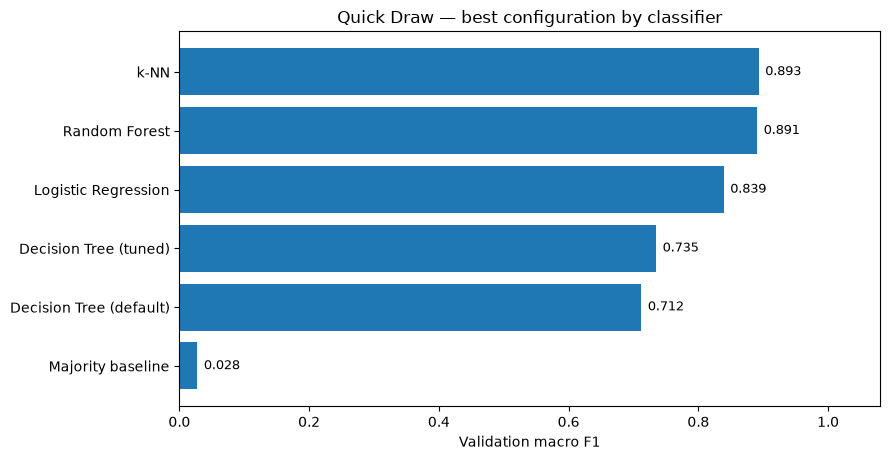

In [26]:
# Keep the strongest setting from each model family (validation macro F1).
classical_all_results = pd.DataFrame(classical_rows)
classical_results_sorted = classical_all_results.sort_values(
    ["Macro F1", "Validation accuracy"], ascending=[False, False]
)
classical_best_per_model = (
    classical_results_sorted.drop_duplicates(subset=["Model"], keep="first")
    .reset_index(drop=True)
)

# Display table, bold the best measured macro F1 where possible.
summary_columns = [
    "Model", "Settings", "Train accuracy", "Train accuracy rows",
    "Validation accuracy", "Macro precision", "Macro recall", "Macro F1",
    "Fit seconds", "Predict seconds"
]
classical_comparison = classical_best_per_model[summary_columns].copy()
display(classical_comparison.round(4))
classical_comparison.to_csv(
    classical_results_dir / "quickdraw_classical_model_comparison_val.csv", index=False
)
classical_all_results.to_csv(
    classical_results_dir / "quickdraw_classical_all_runs_val.csv", index=False
)

best_row = classical_best_per_model.iloc[0]
classical_overall_best_key = f"{best_row['Model']} | {best_row['Settings']}"
classical_best_non_dummy = classical_best_per_model.loc[
    classical_best_per_model["Model"] != "Majority baseline"
].iloc[0]
classical_best_classical_key = (
    f"{classical_best_non_dummy['Model']} | {classical_best_non_dummy['Settings']}"
)
print("Best non-dummy classical model on VALIDATION macro F1:", classical_best_classical_key)

# A compact figure comparing the best configuration of each model family.
plot_models = classical_best_per_model.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.7))
ax.barh(plot_models["Model"], plot_models["Macro F1"])
ax.set_xlim(0, 1.08)
ax.set_xlabel("Validation macro F1")
ax.set_title("Quick Draw — best configuration by classifier")
for j, value in enumerate(plot_models["Macro F1"]):
    ax.text(value + 0.01, j, f"{value:.3f}", va="center", fontsize=9)
fig.tight_layout()
fig.savefig(classical_figures_dir / "quickdraw_classical_model_comparison.png", dpi=160)
plt.show()

### 11.11. Confusion matrix and class-level performance

> The best classical model is examined using an 8 × 8 validation confusion matrix and per-class precision, recall and F1. Rows represent actual classes and columns represent predictions. For the selected k-NN model, **Cat had the lowest recall (64.67%)**, despite high precision (94.63%). The most frequent error was predicting **Apple for Cat** (33 drawings). These class-level differences are obscured by overall accuracy alone.

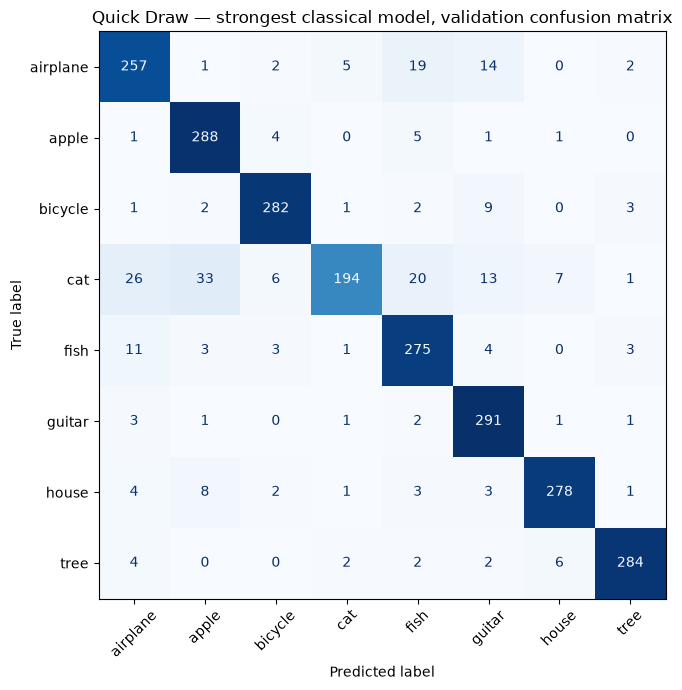

,precision,recall,f1-score,support
airplane,0.8371,0.8567,0.8468,300.0
apple,0.8571,0.9600,0.9057,300.0
bicycle,0.9431,0.9400,0.9416,300.0
cat,0.9463,0.6467,0.7683,300.0
fish,0.8384,0.9167,0.8758,300.0
guitar,0.8635,0.9700,0.9137,300.0
house,0.9488,0.9267,0.9376,300.0
tree,0.9627,0.9467,0.9546,300.0


Most frequent confusion: cat -> apple (count: 33 )


In [28]:
# Use the chosen best classical model; do not refit or touch the final test set.
classical_best_predictions = classical_val_predictions[classical_best_classical_key]
classical_matrix = confusion_matrix(
    cls_y_val, classical_best_predictions, labels=np.arange(len(cls_classes))
)

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(
    confusion_matrix=classical_matrix,
    display_labels=cls_classes
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Quick Draw — strongest classical model, validation confusion matrix")
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
fig.savefig(classical_figures_dir / "quickdraw_classical_best_confusion_val.png", dpi=160)
plt.show()

# Save per-class precision/recall/F1 (more appropriate than one binary TP/FP table).
classical_per_class_dict = classification_report(
    cls_y_val, classical_best_predictions,
    labels=np.arange(len(cls_classes)),
    target_names=cls_classes,
    output_dict=True,
    zero_division=0
)
classical_per_class = pd.DataFrame(classical_per_class_dict).T.loc[cls_classes]
display(classical_per_class.round(4))
classical_per_class.to_csv(classical_results_dir / "quickdraw_classical_per_class_val.csv")

# Show the most common TRUE -> PREDICTED confusion (excluding correct diagonal).
incorrect_only = classical_matrix.copy()
np.fill_diagonal(incorrect_only, 0)
true_id, predicted_id = np.unravel_index(
    incorrect_only.argmax(), incorrect_only.shape
)
if incorrect_only.max() > 0:
    print("Most frequent confusion:",
          f"{cls_classes[true_id]} -> {cls_classes[predicted_id]}",
          "(count:", int(incorrect_only[true_id, predicted_id]), ")")
else:
    true_id, predicted_id = None, None
    print("No off-diagonal errors in this validation confusion matrix.")

### 11.12. Misclassification examples

> A fixed sample of incorrectly classified validation drawings supports qualitative analysis. Several Cat sketches predicted as Apple have rounded outlines, which may help explain the visual confusion; this is an observation about the examples, not proof of its cause.

Validation mistakes: 251 of 2400


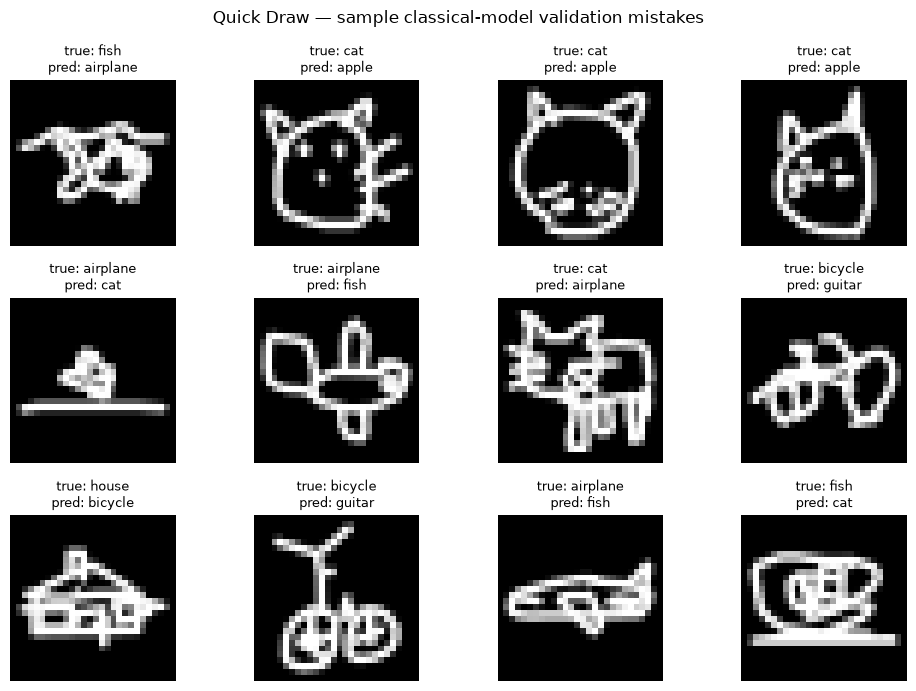

In [29]:
# Display up to 12 incorrectly predicted VAL images, selected with a fixed seed.
wrong_indices = np.flatnonzero(classical_best_predictions != cls_y_val)
print("Validation mistakes:", len(wrong_indices), "of", len(cls_y_val))
if len(wrong_indices) > 0:
    show_n = min(12, len(wrong_indices))
    display_rng = np.random.default_rng(42)
    chosen = display_rng.choice(wrong_indices, size=show_n, replace=False)
    fig, axes = plt.subplots(3, 4, figsize=(10, 7))
    for ax in axes.flat:
        ax.axis("off")
    for ax, idx in zip(axes.flat, chosen):
        ax.imshow(cls_X_val[idx].squeeze(), cmap="gray")
        ax.set_title(
            f"true: {cls_classes[int(cls_y_val[idx])]}\n"
            f"pred: {cls_classes[int(classical_best_predictions[idx])]}",
            fontsize=9
        )
        ax.axis("off")
    fig.suptitle("Quick Draw — sample classical-model validation mistakes")
    fig.tight_layout()
    fig.savefig(classical_figures_dir / "quickdraw_classical_errors_val.png", dpi=160)
    plt.show()
else:
    print("No errors on validation; no error gallery needed.")

### 11.13. Discussion and limitations

> **Model performance.** k-NN (`k = 5`) was the strongest classical classifier on validation macro F1 (**0.8930**), with Random Forest close behind (**0.8907**). Stronger regularisation improved Logistic Regression's validation performance. The default Decision Tree overfit severely, while cross-validated depth and leaf-size constraints improved generalisation. k-NN struggled particularly with Cat recall, as shown in the confusion matrix.

> **Limitations.** These experiments cover eight categories of 28 × 28 grayscale sketches. Flattening the images does not explicitly preserve two-dimensional spatial relationships. The preprocessing checks recorded zero identical images across the train, validation and test partitions, but this does not remove the possibility of visually similar drawings. Training accuracy for k-NN was measured on a smaller sample than for the other models. All model selection has used training and validation data only; the reserved final test set is not yet evaluated.

In [30]:
# Display a result-grounded summary (never hard-code or invent performance values).
classical_best = classical_best_non_dummy
classical_best_train_gap = classical_best["Train accuracy"] - classical_best["Validation accuracy"]
classical_cv_best_f1 = classical_tree_search.best_score_

if true_id is None:
    confusion_description = "No off-diagonal validation errors were recorded."
else:
    confusion_description = (
        f"The most frequent validation confusion was "
        f"**{cls_classes[true_id]} → {cls_classes[predicted_id]}**, "
        f"occurring **{int(incorrect_only[true_id, predicted_id])}** times."
    )

classical_summary = (
    f"**Best classical model (validation macro F1):** "
    f"{classical_best['Model']} with {classical_best['Settings']}. "
    f"It achieved validation accuracy **{classical_best['Validation accuracy']:.4f}** "
    f"and macro F1 **{classical_best['Macro F1']:.4f}**. "
    f"Its recorded training accuracy was **{classical_best['Train accuracy']:.4f}** "
    f"(evaluated on {int(classical_best['Train accuracy rows'])} training images), "
    f"a train–validation accuracy difference of **{classical_best_train_gap:+.4f}**. "
    f"The best Decision Tree configuration obtained mean **10-fold training-only CV "
    f"macro F1 {classical_cv_best_f1:.4f}**. "
    f"{confusion_description}"
)
display(Markdown(classical_summary))
print("Saved comparison tables to:", classical_results_dir)
print("Saved figures to:", classical_figures_dir)


**Best classical model (validation macro F1):** k-NN with k=5, uniform weights, Euclidean distance. It achieved validation accuracy **0.8954** and macro F1 **0.8930**. Its recorded training accuracy was **0.9237** (evaluated on 800 training images), a train–validation accuracy difference of **+0.0283**. The best Decision Tree configuration obtained mean **10-fold training-only CV macro F1 0.7319**. The most frequent validation confusion was **cat → apple**, occurring **33** times.

Saved comparison tables to: /Users/aryan/Documents/Heriot Watt/HWU Year-4/Data Mining & Machine Learning /Courseworks/uickdraw-f20dl-main/results
Saved figures to: /Users/aryan/Documents/Heriot Watt/HWU Year-4/Data Mining & Machine Learning /Courseworks/uickdraw-f20dl-main/figures


## 12. Multi-Layer Perceptron Classification

This section studies a fully connected multi-layer perceptron (MLP) for recognising the eight Quick Draw categories. The input is the same set of 784 normalised pixel values used by the classical classifiers. Unlike a convolutional model, an MLP does not explicitly preserve local two-dimensional image structure.

**Experimental protocol.** The saved 19,200-image training split is used to fit the networks. The 2,400-image validation split is used for early stopping, architecture comparison and class-level analysis. The final 2,400-image test split is not accessed during model selection. The experiments use fixed seeds and record architecture, optimisation settings, training history, accuracy, macro precision, macro recall, macro F1 and runtime.

**Implementation.** `scikit-learn`'s `MLPClassifier` is used with the Adam optimiser and epoch-by-epoch `partial_fit`. This provides reproducible, CPU-compatible experiments in the existing Python environment without introducing a second neural-network framework. An explicit validation-loss checkpoint restores each model's best epoch. We use macro-averaged multiclass scores instead of a single binary TP/FP/TN/FN count because there are eight output categories.

### 12.1. Dataset and reproducibility checks

> The models read the previously prepared dataset without re-downloading, re-sampling, changing class order or recalculating normalisation. The SHA-256 fingerprint can be compared with the dataset used for the CNN experiments; matching settings alone do not guarantee identical sampled examples.

In [31]:
# Verify the saved train/validation arrays and record their hashes.

from pathlib import Path
import hashlib
import time
import copy
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn import __version__ as sklearn_version
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, log_loss, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

mlp_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
mlp_path = mlp_root / "data" / "quickdraw" / "quickdraw_8class_processed.npz"
mlp_results_dir = mlp_root / "results"
mlp_figures_dir = mlp_root / "figures"
mlp_results_dir.mkdir(parents=True, exist_ok=True)
mlp_figures_dir.mkdir(parents=True, exist_ok=True)

if not mlp_path.is_file():
    raise FileNotFoundError(f"Processed data missing: {mlp_path}. Complete Sections 7-9 first.")

# Deliberately load ONLY training and validation data. Test images are sealed until final selection.
with np.load(mlp_path, allow_pickle=False) as saved:
    mlp_Xtrain = saved["X_train"].reshape(-1, 784)
    mlp_ytrain = saved["y_train"]
    mlp_Xval = saved["X_val"].reshape(-1, 784)
    mlp_yval = saved["y_val"]
    mlp_categories = saved["categories"].tolist()

assert mlp_Xtrain.shape == (19200, 784) and mlp_Xval.shape == (2400, 784)
assert mlp_ytrain.shape == (19200,) and mlp_yval.shape == (2400,)
assert mlp_Xtrain.dtype == np.float32 and mlp_Xval.dtype == np.float32
assert np.isfinite(mlp_Xtrain).all() and np.isfinite(mlp_Xval).all()
assert 0 <= mlp_Xtrain.min() <= mlp_Xtrain.max() <= 1
assert 0 <= mlp_Xval.min() <= mlp_Xval.max() <= 1
assert mlp_categories == ["airplane", "apple", "bicycle", "cat", "fish", "guitar", "house", "tree"]
assert np.array_equal(np.bincount(mlp_ytrain, minlength=8), np.full(8, 2400))
assert np.array_equal(np.bincount(mlp_yval, minlength=8), np.full(8, 300))
mlp_labels = np.arange(8)

# Hash the saved bytes without loading the full file into memory at once.
mlp_digest = hashlib.sha256()
with mlp_path.open("rb") as fh:
    for block in iter(lambda: fh.read(1024 * 1024), b""):
        mlp_digest.update(block)
mlp_data_sha256 = mlp_digest.hexdigest()
# Check actual samples too, not only the compressed ZIP serialization.
mlp_content_digest = hashlib.sha256()
for value in (mlp_Xtrain, mlp_ytrain, mlp_Xval, mlp_yval):
    mlp_content_digest.update(np.ascontiguousarray(value).tobytes())
mlp_content_digest.update("|".join(mlp_categories).encode("utf-8"))
mlp_content_sha256 = mlp_content_digest.hexdigest()
(mlp_results_dir / "quickdraw_mlp_dataset_sha256.txt").write_text(
    f"NPZ_FILE_SHA256 {mlp_data_sha256}\n"
    f"TRAIN_VAL_CONTENT_SHA256 {mlp_content_sha256}\n",
    encoding="utf-8"
)
print("Training:", mlp_Xtrain.shape, "| Validation:", mlp_Xval.shape)
print("Categories:", mlp_categories)
print("scikit-learn version:", sklearn_version)
print("Dataset ZIP SHA-256:", mlp_data_sha256)
print("Training/validation content SHA-256:", mlp_content_sha256)
print("Final test split is not loaded in this section.")

Training: (19200, 784) | Validation: (2400, 784)
Categories: ['airplane', 'apple', 'bicycle', 'cat', 'fish', 'guitar', 'house', 'tree']
scikit-learn version: 1.9.1
Dataset ZIP SHA-256: fb96992ea77e6295c59537ba941a195e3d0ba3ccdd1259fe9a5b1af3b06f97a2
Training/validation content SHA-256: 6f566ce85a58ce512716bb08e160102ba978560bcd453ece4c38d0212451532b
Final test split is not loaded in this section.


### 12.2. MLP architecture and training settings

> Each architecture has 784 input features and eight output classes. Hidden-layer depth, hidden-layer width, activation function, L2 regularisation and learning rate are compared across six configurations. All runs use Adam and a fixed seed. The normalised pixel values are already in `[0, 1]`, so no additional scaler is fitted.

> Validation loss is monitored after each epoch, with early stopping when it no longer improves. The weights corresponding to the lowest validation loss are restored. This is distinct from the final model-family ranking, which uses **validation macro F1**. Training and validation accuracy/loss curves allow us to examine overfitting.

In [32]:
# Maximum epochs and patience are adjustable to available CPU resources; record any changes.
MLP_RANDOM_STATE = 42
MLP_MAX_EPOCHS = 20
MLP_PATIENCE = 5
MLP_MIN_DELTA = 0.0005

# Six controlled comparisons: network size/depth, activation, L2 strength, learning rate.
mlp_configs = [
    dict(name="MLP 1", hidden=(128,),         activation="relu", alpha=0.0001, lr=0.0010, batch=128),
    dict(name="MLP 2", hidden=(256, 128),     activation="relu", alpha=0.0001, lr=0.0010, batch=128),
    dict(name="MLP 3", hidden=(256, 128, 64), activation="relu", alpha=0.0001, lr=0.0010, batch=128),
    dict(name="MLP 4", hidden=(256, 128),     activation="tanh", alpha=0.0001, lr=0.0010, batch=128),
    dict(name="MLP 5", hidden=(256, 128),     activation="relu", alpha=0.0100, lr=0.0010, batch=128),
    dict(name="MLP 6", hidden=(256, 128),     activation="relu", alpha=0.0100, lr=0.0005, batch=128),
]
mlp_config_by_name = {config["name"]: config for config in mlp_configs}
mlp_settings_table = pd.DataFrame([{
    "Architecture": c["name"],
    "Hidden layers": "-".join(str(n) for n in c["hidden"]),
    "Activation": c["activation"],
    "L2 alpha": c["alpha"],
    "Learning rate": c["lr"],
    "Batch size": c["batch"],
    "Optimiser": "Adam"
} for c in mlp_configs])
display(mlp_settings_table)

,Architecture,Hidden layers,Activation,L2 alpha,Learning rate,Batch size,Optimiser
0,MLP 1,128,relu,0.0001,0.0010,128,Adam
1,MLP 2,256-128,relu,0.0001,0.0010,128,Adam
2,MLP 3,256-128-64,relu,0.0001,0.0010,128,Adam
3,MLP 4,256-128,tanh,0.0001,0.0010,128,Adam
4,MLP 5,256-128,relu,0.0100,0.0010,128,Adam
5,MLP 6,256-128,relu,0.0100,0.0005,128,Adam


### 12.3. Training procedure

> Each MLP is trained incrementally with Adam, recording training and validation cross-entropy loss and accuracy after every epoch. Training stops when validation loss does not improve sufficiently for five epochs, and the checkpoint with the lowest observed validation loss is restored. Final multiclass scores are calculated from that restored checkpoint.

In [33]:
def mlp_fit_with_history(config, X_fit, y_fit, X_check, y_check, *,
                         max_epochs=MLP_MAX_EPOCHS, patience=MLP_PATIENCE,
                         verbose=True):
    """Train only on X_fit/y_fit; use X_check/y_check for monitoring and stopping.

    Each `partial_fit` is one epoch. Log loss is measured without regularisation
    on BOTH partitions, so the training and validation curves are comparable.
    """
    estimator = MLPClassifier(
        hidden_layer_sizes=tuple(config["hidden"]),
        activation=config["activation"],
        solver="adam", alpha=config["alpha"],
        learning_rate_init=config["lr"],
        batch_size=config["batch"],
        random_state=MLP_RANDOM_STATE,
        shuffle=True,
        early_stopping=False
    )
    history_rows = []
    best_loss = np.inf
    patience_reference_loss = np.inf
    best_epoch = None
    best_weights = None
    epochs_without_improvement = 0
    start_time = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
        # The set of eight class labels is passed on the FIRST incremental fit.
        if epoch == 1:
            estimator.partial_fit(X_fit, y_fit, classes=mlp_labels)
        else:
            estimator.partial_fit(X_fit, y_fit)

        train_probs = estimator.predict_proba(X_fit)
        val_probs = estimator.predict_proba(X_check)
        assert train_probs.shape == (len(y_fit), 8)
        assert val_probs.shape == (len(y_check), 8)
        assert np.isfinite(train_probs).all() and np.isfinite(val_probs).all()
        train_pred = estimator.classes_[np.argmax(train_probs, axis=1)]
        val_pred = estimator.classes_[np.argmax(val_probs, axis=1)]

        # Multiclass cross-entropy for comparable train/validation learning curves.
        train_loss = log_loss(y_fit, train_probs, labels=mlp_labels)
        val_loss = log_loss(y_check, val_probs, labels=mlp_labels)
        history_rows.append({
            "Epoch": epoch,
            "Train loss": float(train_loss),
            "Validation loss": float(val_loss),
            "Train accuracy": float(accuracy_score(y_fit, train_pred)),
            "Validation accuracy": float(accuracy_score(y_check, val_pred)),
            "Validation macro F1": float(f1_score(y_check, val_pred, average="macro", zero_division=0))
        })

        # Save independent copies: later training updates the live weight arrays.
        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch
            best_weights = (
                [w.copy() for w in estimator.coefs_],
                [b.copy() for b in estimator.intercepts_]
            )
        if val_loss < patience_reference_loss - MLP_MIN_DELTA:
            patience_reference_loss = val_loss
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if verbose and (epoch == 1 or epoch % 5 == 0):
            print(f"{config['name']}: epoch {epoch:02d} | "
                  f"train acc {history_rows[-1]['Train accuracy']:.4f} | "
                  f"val acc {history_rows[-1]['Validation accuracy']:.4f} | "
                  f"val loss {val_loss:.4f}")
        if epochs_without_improvement >= patience:
            if verbose:
                print(f"{config['name']}: early stop at epoch {epoch}; best epoch {best_epoch}.")
            break

    # Restore the checkpoint that had the lowest validation loss.
    assert best_weights is not None and best_epoch is not None
    estimator.coefs_, estimator.intercepts_ = best_weights
    elapsed = time.perf_counter() - start_time
    history = pd.DataFrame(history_rows)
    predictions = estimator.predict(X_check)
    training_predictions = estimator.predict(X_fit)
    assert set(np.unique(predictions)).issubset(set(mlp_labels))
    result = {
        "model": estimator,
        "history": history,
        "predictions": predictions,
        "best_epoch": int(best_epoch),
        "epochs_run": int(len(history)),
        "best_val_loss": float(best_loss),
        "train_accuracy": float(accuracy_score(y_fit, training_predictions)),
        "validation_accuracy": float(accuracy_score(y_check, predictions)),
        "macro_precision": float(precision_score(y_check, predictions, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_check, predictions, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_check, predictions, average="macro", zero_division=0)),
        "fit_and_monitor_seconds": float(elapsed)
    }
    return result

print("MLP training/evaluation procedure ready.")

MLP training/evaluation procedure ready.


### 12.4. Architecture comparison

> The six configurations are trained separately on the same 19,200 drawings and evaluated on the same 2,400 validation drawings. The comparison table reports the architecture, settings, selected epoch, measured runtime and macro-averaged multiclass metrics. The highest validation macro F1 is highlighted. Training-versus-validation accuracy provides an initial indication of overfitting.

In [35]:
mlp_runs = {}
mlp_rows = []
mlp_history_rows = []
for config in mlp_configs:
    print("\nTraining", config["name"], "with hidden layers", config["hidden"])
    run = mlp_fit_with_history(config, mlp_Xtrain, mlp_ytrain, mlp_Xval, mlp_yval)
    mlp_runs[config["name"]] = run
    run["history"].assign(Architecture=config["name"]).to_csv(
        mlp_results_dir / f"quickdraw_mlp_{config['name'].lower().replace(' ', '_')}_history.csv",
        index=False
    )
    mlp_history_rows.append(run["history"].assign(Architecture=config["name"]))
    mlp_rows.append({
        "Architecture": config["name"],
        "Hidden layers": "-".join(str(x) for x in config["hidden"]),
        "Activation": config["activation"],
        "L2 alpha": config["alpha"],
        "Learning rate": config["lr"],
        "Batch size": config["batch"],
        "Best epoch": run["best_epoch"],
        "Epochs run": run["epochs_run"],
        "Train accuracy": run["train_accuracy"],
        "Validation accuracy": run["validation_accuracy"],
        "Macro precision": run["macro_precision"],
        "Macro recall": run["macro_recall"],
        "Macro F1": run["macro_f1"],
        "Best validation loss": run["best_val_loss"],
        "Fit + monitoring (s)": run["fit_and_monitor_seconds"]
    })

mlp_comparison = pd.DataFrame(mlp_rows).sort_values(
    ["Macro F1", "Validation accuracy"], ascending=False
).reset_index(drop=True)
mlp_best_name = mlp_comparison.iloc[0]["Architecture"]
mlp_best_config = mlp_config_by_name[mlp_best_name]
mlp_best = mlp_runs[mlp_best_name]
mlp_comparison.to_csv(mlp_results_dir / "quickdraw_mlp_architecture_comparison_val.csv", index=False)
mlp_histories = pd.concat(mlp_history_rows, ignore_index=True)
mlp_histories.to_csv(mlp_results_dir / "quickdraw_mlp_all_epoch_history.csv", index=False)

# Highlight the measured winner without manually hard-coding any scores.
try:
    display(mlp_comparison.style.format({
        "Train accuracy": "{:.3f}", "Validation accuracy": "{:.3f}",
        "Macro precision": "{:.3f}", "Macro recall": "{:.3f}", "Macro F1": "{:.3f}",
        "Best validation loss": "{:.3f}", "Fit + monitoring (s)": "{:.1f}"
    }).highlight_max(subset=["Macro F1"], color="#c9e7d0"))
except (AttributeError, ImportError):
    display(mlp_comparison.round(3))  # Fallback if optional Jinja2 is unavailable.
print(f"Best MLP on validation macro F1: {mlp_best_name} "
      f"({mlp_best['macro_f1']:.4f}), selected epoch {mlp_best['best_epoch']}.")

# Persist the selected model for inference without having to rerun all architectures.
# Only load this joblib file from a trusted source; sklearn's pickle format is not a secure exchange format.
import joblib
joblib.dump({
    "model": mlp_best["model"],
    "categories": mlp_categories,
    "configuration": mlp_best_config,
    "train_val_content_sha256": mlp_content_sha256
}, mlp_results_dir / "quickdraw_mlp_best_inference_model.joblib", compress=3)
print("Saved inference checkpoint for the selected MLP architecture.")


Training MLP 1 with hidden layers (128,)
MLP 1: epoch 01 | train acc 0.8540 | val acc 0.8467 | val loss 0.5042
MLP 1: epoch 05 | train acc 0.9223 | val acc 0.8925 | val loss 0.3925
MLP 1: epoch 10 | train acc 0.9566 | val acc 0.8946 | val loss 0.3873
MLP 1: early stop at epoch 12; best epoch 7.

Training MLP 2 with hidden layers (256, 128)
MLP 2: epoch 01 | train acc 0.8766 | val acc 0.8646 | val loss 0.4493
MLP 2: epoch 05 | train acc 0.9608 | val acc 0.8996 | val loss 0.3546
MLP 2: epoch 10 | train acc 0.9759 | val acc 0.8904 | val loss 0.4821
MLP 2: early stop at epoch 10; best epoch 5.

Training MLP 3 with hidden layers (256, 128, 64)
MLP 3: epoch 01 | train acc 0.8782 | val acc 0.8712 | val loss 0.4369
MLP 3: epoch 05 | train acc 0.9492 | val acc 0.8929 | val loss 0.3757
MLP 3: epoch 10 | train acc 0.9560 | val acc 0.8904 | val loss 0.5243
MLP 3: early stop at epoch 10; best epoch 5.

Training MLP 4 with hidden layers (256, 128)
MLP 4: epoch 01 | train acc 0.8618 | val acc 0.8575

,Architecture,Hidden layers,Activation,L2 alpha,Learning rate,Batch size,Best epoch,Epochs run,Train accuracy,Validation accuracy,Macro precision,Macro recall,Macro F1,Best validation loss,Fit + monitoring (s)
0,MLP 5,256-128,relu,0.010000,0.001000,128,5,10,0.958,0.903,0.905,0.903,0.904,0.359,2.5
1,MLP 2,256-128,relu,0.000100,0.001000,128,5,10,0.961,0.900,0.901,0.900,0.900,0.355,2.5
2,MLP 6,256-128,relu,0.010000,0.000500,128,6,11,0.947,0.896,0.897,0.896,0.896,0.359,2.9
3,MLP 1,128,relu,0.000100,0.001000,128,7,12,0.939,0.895,0.897,0.895,0.896,0.383,1.7
4,MLP 4,256-128,tanh,0.000100,0.001000,128,5,10,0.934,0.895,0.896,0.895,0.895,0.375,2.5
5,MLP 3,256-128-64,relu,0.000100,0.001000,128,5,10,0.949,0.893,0.895,0.893,0.893,0.376,2.9


Best MLP on validation macro F1: MLP 5 (0.9035), selected epoch 5.
Saved inference checkpoint for the selected MLP architecture.


### 12.5. Learning curves and model complexity

> Training and validation accuracy/loss curves are plotted for all six architectures. Larger gaps can indicate overfitting, while low scores on both partitions can indicate underfitting. The strongest model (MLP 5) achieved **95.82% training accuracy** and **90.33% validation accuracy**, a gap of about **5.48 percentage points**. Its lowest validation loss occurred at epoch **5**; training stopped after **10** epochs, with the best weights restored.

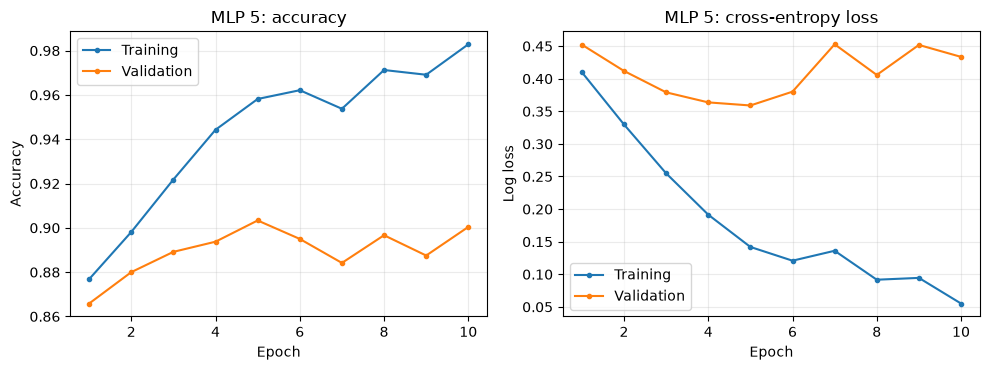

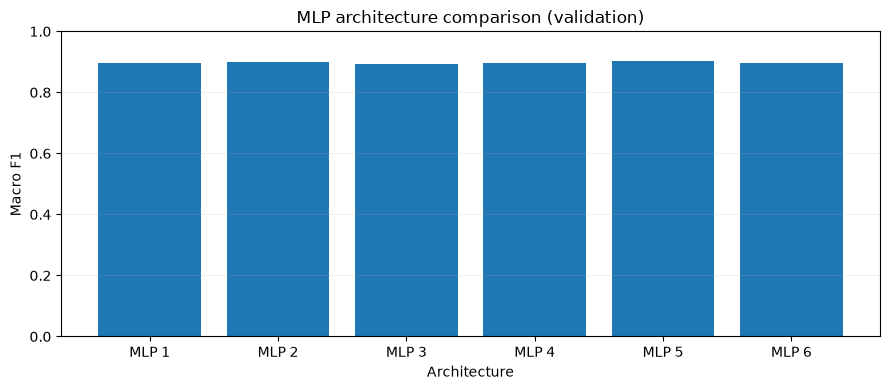

In [37]:
# Save both accuracy and log-loss curves for every architecture.
for config in mlp_configs:
    history = mlp_runs[config["name"]]["history"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    axes[0].plot(history["Epoch"], history["Train accuracy"], marker=".", label="Training")
    axes[0].plot(history["Epoch"], history["Validation accuracy"], marker=".", label="Validation")
    axes[0].set(title=f"{config['name']}: accuracy", xlabel="Epoch", ylabel="Accuracy")
    axes[0].legend()
    axes[0].grid(alpha=0.25)
    axes[1].plot(history["Epoch"], history["Train loss"], marker=".", label="Training")
    axes[1].plot(history["Epoch"], history["Validation loss"], marker=".", label="Validation")
    axes[1].set(title=f"{config['name']}: cross-entropy loss", xlabel="Epoch", ylabel="Log loss")
    axes[1].legend()
    axes[1].grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(mlp_figures_dir / f"quickdraw_mlp_{config['name'].lower().replace(' ', '_')}_curves.png", dpi=160)
    if config["name"] == mlp_best_name:
        plt.show()
    else:
        plt.close(fig)

# Compare validation macro F1 across architectures (not only the winning model).
fig, ax = plt.subplots(figsize=(9, 4))
ordered = mlp_comparison.sort_values("Architecture")
ax.bar(ordered["Architecture"], ordered["Macro F1"])
ax.set(title="MLP architecture comparison (validation)", xlabel="Architecture", ylabel="Macro F1")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(mlp_figures_dir / "quickdraw_mlp_architecture_comparison.png", dpi=160)
plt.show()

### 12.6. Best-model confusion matrix and error analysis

> The selected MLP is evaluated using an 8 × 8 validation confusion matrix, per-class precision, recall and F1, and a sample of incorrect predictions. It correctly classified **2,168 of 2,400** validation drawings. Recall was highest for **Guitar and House (95.33%)** and lowest for **Airplane (81.00%)**. The most frequent error was **Airplane predicted as Cat** (22 images). The sample error gallery includes simplified airplane and cat outlines that illustrate the visual ambiguity.

,precision,recall,f1-score,support
airplane,0.8556,0.8100,0.8322,300.0
apple,0.9617,0.9200,0.9404,300.0
bicycle,0.9302,0.9333,0.9318,300.0
cat,0.7932,0.8567,0.8237,300.0
fish,0.9020,0.8900,0.8960,300.0
guitar,0.9051,0.9533,0.9286,300.0
house,0.9316,0.9533,0.9423,300.0
tree,0.9579,0.9100,0.9333,300.0


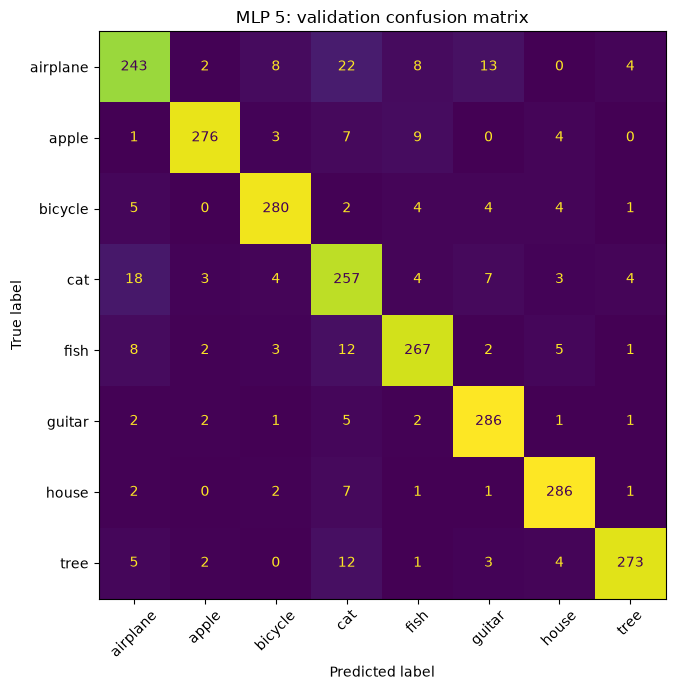

Correct / incorrect: 2168 / 232


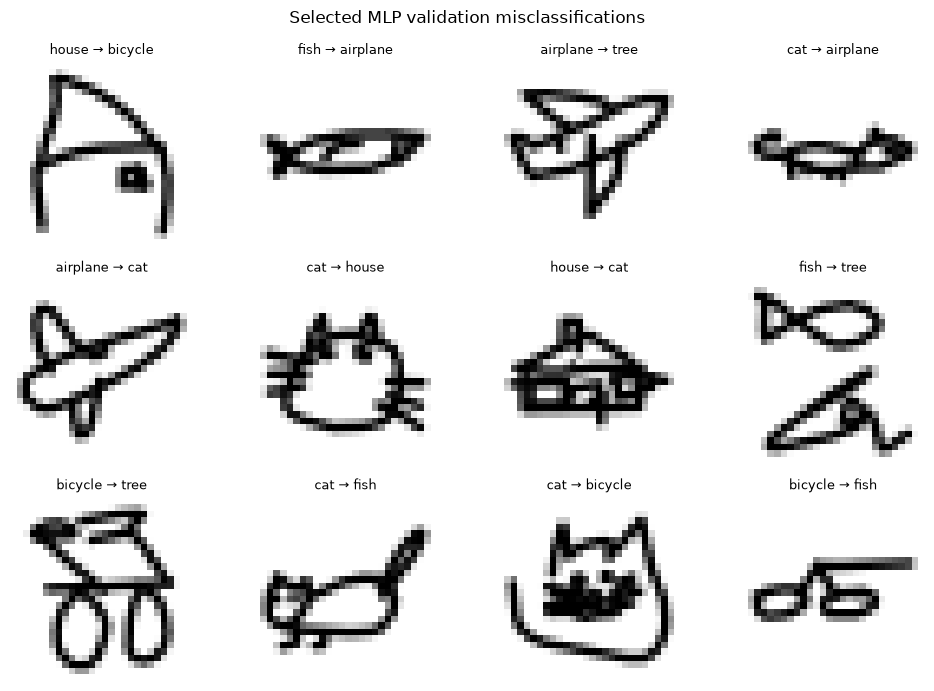

Most frequent confusion: airplane -> cat : 22


In [38]:
mlp_best_predictions = mlp_best["predictions"]
mlp_confusion = confusion_matrix(mlp_yval, mlp_best_predictions, labels=mlp_labels)
assert mlp_confusion.shape == (8, 8)
assert np.array_equal(mlp_confusion.sum(axis=1), np.full(8, 300))
assert mlp_confusion.sum() == 2400
assert np.isclose(np.trace(mlp_confusion) / 2400, mlp_best["validation_accuracy"])

pd.DataFrame(mlp_confusion, index=mlp_categories, columns=mlp_categories).to_csv(
    mlp_results_dir / "quickdraw_mlp_best_confusion_val.csv"
)
per_class_report = classification_report(
    mlp_yval, mlp_best_predictions, labels=mlp_labels,
    target_names=mlp_categories, output_dict=True, zero_division=0
)
mlp_per_class = pd.DataFrame(per_class_report).T.loc[mlp_categories]
mlp_per_class.to_csv(mlp_results_dir / "quickdraw_mlp_best_per_class_val.csv")
display(mlp_per_class.round(4))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(mlp_confusion, display_labels=mlp_categories).plot(
    ax=ax, xticks_rotation=45, colorbar=False, values_format="d"
)
ax.set_title(f"{mlp_best_name}: validation confusion matrix")
fig.tight_layout()
fig.savefig(mlp_figures_dir / "quickdraw_mlp_best_confusion_val.png", dpi=160)
plt.show()

errors = np.flatnonzero(mlp_yval != mlp_best_predictions)
print("Correct / incorrect:", int(np.trace(mlp_confusion)), "/", len(errors))
if len(errors):
    sample_rng = np.random.default_rng(42)
    examples = sample_rng.choice(errors, size=min(12, len(errors)), replace=False)
    fig, axes = plt.subplots(3, 4, figsize=(10, 7))
    for ax, example_id in zip(axes.flat, examples):
        ax.imshow(mlp_Xval[example_id].reshape(28, 28), cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(f"{mlp_categories[mlp_yval[example_id]]} → "
                     f"{mlp_categories[mlp_best_predictions[example_id]]}", fontsize=9)
        ax.axis("off")
    for ax in axes.flat[len(examples):]:
        ax.axis("off")
    fig.suptitle("Selected MLP validation misclassifications")
    fig.tight_layout()
    fig.savefig(mlp_figures_dir / "quickdraw_mlp_best_errors_val.png", dpi=160)
    plt.show()

# Summarise the dominant off-diagonal error without inventing interpretation.
mlp_offdiag = mlp_confusion.copy()
np.fill_diagonal(mlp_offdiag, 0)
if mlp_offdiag.max() > 0:
    src_idx, pred_idx = np.unravel_index(np.argmax(mlp_offdiag), mlp_offdiag.shape)
    print("Most frequent confusion:", mlp_categories[src_idx], "->",
          mlp_categories[pred_idx], ":", mlp_offdiag[src_idx, pred_idx])

### 12.7. Effect of training-set size

> The selected MLP architecture is fitted using stratified subsets of 40%, 70% and 100% of the existing training partition. The smaller experiments retain an internal training-only holdout; the common validation set is used for comparison. Validation accuracy increased from **87.17%** (7,680 training images) to **88.54%** (13,440) and **90.33%** (19,200). Differences in stopping epoch and training size should be considered when interpreting this trend. The final test set remains unused.


Training-size study: 70% of original training split
Internal holdout acc: 0.8889 | fixed validation acc: 0.8854

Training-size study: 40% of original training split
Internal holdout acc: 0.8669 | fixed validation acc: 0.8717


,Training fraction,Training rows,Internal holdout rows,Train accuracy,Internal holdout accuracy,Validation accuracy,Validation macro F1,Best epoch,Fit + monitoring (s)
2,0.4,7680,11520,0.9306,0.8669,0.8717,0.8707,4,1.0949
1,0.7,13440,5760,0.9632,0.8889,0.8854,0.8838,6,2.3842
0,1.0,19200,0,0.9582,NaN,0.9033,0.9035,5,2.4985


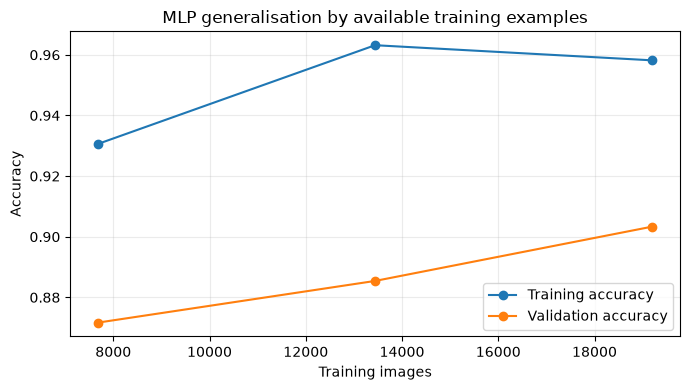

In [41]:
# Additional experiments involve two more network fits. Keep enabled for a fuller
# training-size/overfitting analysis; disable only if Mac runtime/memory is prohibitive.
RUN_MLP_TRAINING_SIZE_STUDY = True

mlp_training_size_rows = [{
    "Training fraction": 1.0, "Training rows": len(mlp_ytrain),
    "Internal holdout rows": 0,
    "Train accuracy": mlp_best["train_accuracy"],
    "Internal holdout accuracy": np.nan,
    "Validation accuracy": mlp_best["validation_accuracy"],
    "Validation macro F1": mlp_best["macro_f1"],
    "Best epoch": mlp_best["best_epoch"],
    "Fit + monitoring (s)": mlp_best["fit_and_monitor_seconds"]
}]

if RUN_MLP_TRAINING_SIZE_STUDY:
    for fraction in (0.70, 0.40):
        selected, holdout = train_test_split(
            np.arange(len(mlp_ytrain)), train_size=fraction,
            stratify=mlp_ytrain, random_state=MLP_RANDOM_STATE
        )
        print(f"\nTraining-size study: {fraction:.0%} of original training split")
        subset_run = mlp_fit_with_history(
            mlp_best_config, mlp_Xtrain[selected], mlp_ytrain[selected],
            mlp_Xval, mlp_yval, verbose=False
        )
        internal_pred = subset_run["model"].predict(mlp_Xtrain[holdout])
        mlp_training_size_rows.append({
            "Training fraction": fraction, "Training rows": len(selected),
            "Internal holdout rows": len(holdout),
            "Train accuracy": subset_run["train_accuracy"],
            "Internal holdout accuracy": accuracy_score(mlp_ytrain[holdout], internal_pred),
            "Validation accuracy": subset_run["validation_accuracy"],
            "Validation macro F1": subset_run["macro_f1"],
            "Best epoch": subset_run["best_epoch"],
            "Fit + monitoring (s)": subset_run["fit_and_monitor_seconds"]
        })
        print("Internal holdout acc:", round(mlp_training_size_rows[-1]["Internal holdout accuracy"], 4),
              "| fixed validation acc:", round(subset_run["validation_accuracy"], 4))

mlp_training_size_table = pd.DataFrame(mlp_training_size_rows).sort_values("Training fraction")
mlp_training_size_table.to_csv(
    mlp_results_dir / "quickdraw_mlp_training_size_val.csv", index=False
)
display(mlp_training_size_table.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(mlp_training_size_table["Training rows"], mlp_training_size_table["Train accuracy"], marker="o", label="Training accuracy")
ax.plot(mlp_training_size_table["Training rows"], mlp_training_size_table["Validation accuracy"], marker="o", label="Validation accuracy")
ax.set(title="MLP generalisation by available training examples", xlabel="Training images", ylabel="Accuracy")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(mlp_figures_dir / "quickdraw_mlp_training_size.png", dpi=160)
plt.show()

### 12.8. Training-only cross-validation

> Ten-fold stratified cross-validation is implemented as an additional training-only evaluation, using a fixed epoch budget without validation-fold early stopping. It was **not executed for the MLP experiments**, because of its additional computational cost, and no cross-validation score is claimed. Architecture selection instead uses the separate 2,400-image validation partition. The Decision Tree experiments include completed ten-fold cross-validation.

In [42]:
RUN_MLP_10FOLD_CV = False
MLP_CV_EPOCHS = 15  # Explicitly different budget from the selected model's early-stopped run.

if RUN_MLP_10FOLD_CV:
    cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=MLP_RANDOM_STATE)
    cv_results = []
    for fold_no, (train_idx, held_idx) in enumerate(cv.split(mlp_Xtrain, mlp_ytrain), 1):
        # The fold's held-out examples are NEVER used to fit or stop this model.
        cv_estimator = MLPClassifier(
            hidden_layer_sizes=tuple(mlp_best_config["hidden"]),
            activation=mlp_best_config["activation"],
            solver="adam", alpha=mlp_best_config["alpha"],
            learning_rate_init=mlp_best_config["lr"],
            batch_size=mlp_best_config["batch"],
            random_state=MLP_RANDOM_STATE,
            max_iter=MLP_CV_EPOCHS, early_stopping=False
        )
        with warnings.catch_warnings(record=True) as caught:
            from sklearn.exceptions import ConvergenceWarning
            warnings.simplefilter("always", ConvergenceWarning)
            cv_estimator.fit(mlp_Xtrain[train_idx], mlp_ytrain[train_idx])
        fold_pred = cv_estimator.predict(mlp_Xtrain[held_idx])
        cv_results.append({
            "Fold": fold_no,
            "Accuracy": accuracy_score(mlp_ytrain[held_idx], fold_pred),
            "Macro F1": f1_score(mlp_ytrain[held_idx], fold_pred, average="macro", zero_division=0),
            "Convergence warnings": sum(issubclass(w.category, ConvergenceWarning) for w in caught)
        })
        print(f"CV fold {fold_no}/10: macro F1 = {cv_results[-1]['Macro F1']:.4f}")
    mlp_cv_table = pd.DataFrame(cv_results)
    mlp_cv_table.to_csv(mlp_results_dir / "quickdraw_mlp_training_only_cv.csv", index=False)
    print("CV mean macro F1:", mlp_cv_table["Macro F1"].mean(),
          "| std:", mlp_cv_table["Macro F1"].std())
    display(mlp_cv_table)
else:
    print("MLP ten-fold cross-validation was NOT run (optional, compute-intensive).")

MLP ten-fold cross-validation was NOT run (optional, compute-intensive).


### 12.9. Comparison with classical classifiers

> The MLP and classical models are compared using identical training and validation partitions and the same macro-averaged measures. **MLP 5** achieved **90.33% validation accuracy** and **0.9035 macro F1**, compared with **89.54% accuracy** and **0.8930 macro F1** for the strongest classical model, k-NN. The MLP classified **19 additional validation drawings correctly**. Comparisons with the CNN require verification that the CNN models use the same images, labels and data split.

In [44]:
# Reuse the already generated classical-model results rather than retraining their models.
classical_csv = mlp_results_dir / "quickdraw_classical_model_comparison_val.csv"
if not classical_csv.is_file():
    raise FileNotFoundError(
        f"Missing {classical_csv}. Run Section 11.10 to save the classical comparison first."
    )

classic = pd.read_csv(classical_csv)
required_cols = ["Model", "Settings", "Validation accuracy", "Macro precision", "Macro recall", "Macro F1"]
assert set(required_cols).issubset(classic.columns), "Classical CSV columns differ from expected schema."
combined_rows = classic[required_cols].copy()
combined_rows["Representation"] = "784 flattened pixels"
mlp_row = pd.DataFrame([{
    "Model": "MLP", "Settings": f"{mlp_best_name}: {mlp_best_config['hidden']} "
                             f"{mlp_best_config['activation']}, alpha={mlp_best_config['alpha']}, "
                             f"lr={mlp_best_config['lr']}",
    "Validation accuracy": mlp_best["validation_accuracy"],
    "Macro precision": mlp_best["macro_precision"],
    "Macro recall": mlp_best["macro_recall"],
    "Macro F1": mlp_best["macro_f1"],
    "Representation": "784 flattened pixels"
}])
combined = pd.concat([combined_rows, mlp_row], ignore_index=True)
combined = combined.sort_values(["Macro F1", "Validation accuracy"], ascending=False).reset_index(drop=True)
combined = combined[["Model", "Representation", "Settings", "Validation accuracy",
                     "Macro precision", "Macro recall", "Macro F1"]]
combined.to_csv(mlp_results_dir / "quickdraw_classical_mlp_comparison_val.csv", index=False)
try:
    display(combined.style.format({
        "Validation accuracy": "{:.3f}", "Macro precision": "{:.3f}",
        "Macro recall": "{:.3f}", "Macro F1": "{:.3f}"
    }).highlight_max(subset=["Macro F1"], color="#c9e7d0"))
except (AttributeError, ImportError):
    display(combined.round(3))  # Fallback if optional Jinja2 is unavailable.
print("CNN comparison remains pending: do not combine independent validation runs "
      "until the dataset hashes, labels and split agree.")

,Model,Representation,Settings,Validation accuracy,Macro precision,Macro recall,Macro F1
0,MLP,784 flattened pixels,"MLP 5: (256, 128) relu, alpha=0.01, lr=0.001",0.903,0.905,0.903,0.904
1,k-NN,784 flattened pixels,"k=5, uniform weights, Euclidean distance",0.895,0.900,0.895,0.893
2,Random Forest,784 flattened pixels,"100 trees, min_samples_leaf=2",0.891,0.891,0.891,0.891
3,Logistic Regression,784 flattened pixels,"C=0.1, solver=lbfgs",0.839,0.839,0.839,0.839
4,Decision Tree (tuned),784 flattened pixels,"criterion=entropy, max_depth=12, min_samples_leaf=5",0.734,0.737,0.734,0.735
5,Decision Tree (default),784 flattened pixels,"criterion=gini, max_depth=None, min_samples_leaf=1",0.712,0.712,0.712,0.712
6,Majority baseline,784 flattened pixels,most_frequent,0.125,0.016,0.125,0.028


CNN comparison remains pending: do not combine independent validation runs until the dataset hashes, labels and split agree.


### 12.10. Reserved final test evaluation

> **Do not enable this cell during model tuning.** When the architecture has been selected and reviewed with the CNN experiments, one final test evaluation can be performed. The code intentionally does not read the test partition unless the explicit flag is changed. Test-set metrics must never be used to choose or modify architectures.

In [45]:
RUN_FINAL_MLP_TEST = False  # Enable ONCE, after all model choices are frozen with the team.

if RUN_FINAL_MLP_TEST:
    with np.load(mlp_path, allow_pickle=False) as sealed:
        X_final = sealed["X_test"]
        y_final = sealed["y_test"]
    assert X_final.shape == (2400, 28, 28, 1)
    assert y_final.shape == (2400,)
    assert np.array_equal(np.bincount(y_final, minlength=8), np.full(8, 300))
    final_pred = mlp_best["model"].predict(X_final.reshape(-1, 784))
    final_metrics = pd.DataFrame([{
        "Model": "MLP", "Architecture": mlp_best_name,
        "Test accuracy": accuracy_score(y_final, final_pred),
        "Test macro precision": precision_score(y_final, final_pred, average="macro", zero_division=0),
        "Test macro recall": recall_score(y_final, final_pred, average="macro", zero_division=0),
        "Test macro F1": f1_score(y_final, final_pred, average="macro", zero_division=0)
    }])
    final_metrics.to_csv(mlp_results_dir / "quickdraw_mlp_locked_final_test.csv", index=False)
    display(final_metrics)
    pd.DataFrame(confusion_matrix(y_final, final_pred, labels=mlp_labels),
                 index=mlp_categories, columns=mlp_categories).to_csv(
                     mlp_results_dir / "quickdraw_mlp_locked_final_test_confusion.csv"
                 )
    print("Final test examined: treat these results as final; do not retune from them.")
else:
    print("Final MLP test remains sealed. Selection uses training + validation only.")

Final MLP test remains sealed. Selection uses training + validation only.


### 12.11. Results and reproducibility

> The following cell summarises the measured best-architecture settings and exports the architecture comparison, per-epoch histories, confusion matrix, class-level measures, training-size results and reproducibility hashes. These outputs support independent checking and comparison with the CNN experiments.

In [46]:
# Summarise only computed values and write a small portable CSV review package.
from zipfile import ZipFile, ZIP_DEFLATED

mlp_gap = mlp_best["train_accuracy"] - mlp_best["validation_accuracy"]
mlp_summary = (
    f"**Best MLP:** {mlp_best_name}, hidden layers {mlp_best_config['hidden']}, "
    f"activation={mlp_best_config['activation']}, alpha={mlp_best_config['alpha']}, "
    f"learning rate={mlp_best_config['lr']}. "
    f"Validation accuracy **{mlp_best['validation_accuracy']:.4f}**, "
    f"macro F1 **{mlp_best['macro_f1']:.4f}**; "
    f"training accuracy **{mlp_best['train_accuracy']:.4f}** "
    f"(training-validation gap **{mlp_gap:+.4f}**), "
    f"best epoch **{mlp_best['best_epoch']}**. "
    f"Training included patience-based stopping and restoration of the best checkpoint."
)
display(Markdown(mlp_summary))
# Explicit inclusion list avoids accidentally packaging stale CV or test CSVs
# left over from an earlier experimental run in the same results directory.
import json
run_manifest = {
    "dataset_file_sha256": mlp_data_sha256,
    "train_val_content_sha256": mlp_content_sha256,
    "scikit_learn_version": sklearn_version,
    "max_epochs": MLP_MAX_EPOCHS,
    "early_stopping_patience": MLP_PATIENCE,
    "architectures_trained": len(mlp_runs),
    "training_size_study_executed": bool(RUN_MLP_TRAINING_SIZE_STUDY),
    "mlp_ten_fold_cv_executed": bool(RUN_MLP_10FOLD_CV),
    "final_test_accessed": bool(RUN_FINAL_MLP_TEST),
    "best_model": mlp_best_name
}
manifest_path = mlp_results_dir / "quickdraw_mlp_run_manifest.json"
manifest_path.write_text(json.dumps(run_manifest, indent=2), encoding="utf-8")
review_files = [
    mlp_results_dir / "quickdraw_mlp_architecture_comparison_val.csv",
    mlp_results_dir / "quickdraw_mlp_all_epoch_history.csv",
    mlp_results_dir / "quickdraw_mlp_best_confusion_val.csv",
    mlp_results_dir / "quickdraw_mlp_best_per_class_val.csv",
    mlp_results_dir / "quickdraw_mlp_training_size_val.csv",
    mlp_results_dir / "quickdraw_classical_mlp_comparison_val.csv",
    mlp_results_dir / "quickdraw_mlp_dataset_sha256.txt",
    manifest_path
]
review_files += [mlp_results_dir / f"quickdraw_mlp_{c['name'].lower().replace(' ', '_')}_history.csv" for c in mlp_configs]
if RUN_MLP_10FOLD_CV:
    review_files.append(mlp_results_dir / "quickdraw_mlp_training_only_cv.csv")
if RUN_FINAL_MLP_TEST:
    review_files.extend([
        mlp_results_dir / "quickdraw_mlp_locked_final_test.csv",
        mlp_results_dir / "quickdraw_mlp_locked_final_test_confusion.csv"
    ])
review_zip = mlp_results_dir / "quickdraw_mlp_review.zip"
with ZipFile(review_zip, "w", ZIP_DEFLATED) as bundle:
    for source in review_files:
        if not source.exists():
            raise FileNotFoundError(f"Expected review result missing: {source}")
        bundle.write(source, arcname=source.name)
print("MLP review ZIP:", review_zip)
print("CSV/figure results:", mlp_results_dir, "and", mlp_figures_dir)
print("Training/validation fingerprint for CNN verification:", mlp_content_sha256)

**Best MLP:** MLP 5, hidden layers (256, 128), activation=relu, alpha=0.01, learning rate=0.001. Validation accuracy **0.9033**, macro F1 **0.9035**; training accuracy **0.9582** (training-validation gap **+0.0548**), best epoch **5**. Training included patience-based stopping and restoration of the best checkpoint.

MLP review ZIP: /Users/aryan/Documents/Heriot Watt/HWU Year-4/Data Mining & Machine Learning /Courseworks/uickdraw-f20dl-main/results/quickdraw_mlp_review.zip
CSV/figure results: /Users/aryan/Documents/Heriot Watt/HWU Year-4/Data Mining & Machine Learning /Courseworks/uickdraw-f20dl-main/results and /Users/aryan/Documents/Heriot Watt/HWU Year-4/Data Mining & Machine Learning /Courseworks/uickdraw-f20dl-main/figures
Training/validation fingerprint for CNN verification: 6f566ce85a58ce512716bb08e160102ba978560bcd453ece4c38d0212451532b


**Discussion and limitations.** Among six architectures, **MLP 5** (hidden layers 256–128, ReLU, `alpha = 0.01`, learning rate 0.001) had the highest validation macro F1 (**0.9035**). It outperformed the corresponding weaker-L2 model (MLP 2, **0.8998**) and the three-hidden-layer configuration (MLP 3, **0.8930**) on this validation split. Stronger regularisation helped slightly here, while greater depth did not automatically improve recognition. Its training–validation gap indicates some overfitting, while the early-stopping and training-size studies provide supporting evidence about generalisation. The improvement over k-NN is modest, and a single validation split does not establish statistical superiority. CNN comparison and final test evaluation remain outstanding.